# **Combining dataset: data scrapping from detik, cnn, kompas and suara with keyword timnas indonesia**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import re

In [ ]:
# load dataset hasil scraping dari website
ami = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/detikArticle3_cleaned_fix.csv')
denta1 = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/mamamia.csv')
denta2 = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/cnn.csv')
surya1 = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/cnn2.csv')
leo = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/cnn3.csv')
surya2 = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/cnn_421-840.csv')
dea = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/kompas_clean1.csv')
basudewa = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/suara_clean4.csv')

In [ ]:
# menggabungkan semua dataset menjadi 1 data frame
combined_csv = pd.concat([ami, basudewa, denta1, dea, denta2, leo, surya1, surya2], ignore_index=True)
combined_csv.head()

,title,month,content
0,Kiper Vietnam Puji Pemain-pemain Muda Timnas I...,Desember,Timnas Vietnam menang atas Indonesia 1-0 di la...
1,Piala AFF 2024: Ketum PSSI Sanjung Penampilan ...,Desember,Timnas Indonesia kalah melawan Vietnam. Ketua ...
2,Hitung-hitungan Indonesia Lolos ke Semifinal P...,Desember,Timnas Indonesia kalah dari Vietnam 0-1 di lan...
3,Statistik Indonesia Vs Vietnam: Timnas Tak Ber...,Desember,Tim nasional Indonesia takluk dari Vietnam di ...
4,"Kerepotan & Ditahan Imbang Laos, Pelajaran Pen...",Desember,Tim nasional Indonesia harus puas dengan hasil...


In [ ]:
# cek ukuran data frame
combined_csv.shape

(9607, 3)

In [ ]:
# save data
combined_csv.to_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/raw_dataset.csv', index=False)

# **Data Cleaning: remove nan values and duplicates**

In [ ]:
# cek nan values
combined_csv.isna().sum()

,0
title,97
month,115
content,176


In [ ]:
# menghapus semua nilai nan
combined_csv = combined_csv.dropna()

In [ ]:
# cek ulang nilai nan
combined_csv.isna().sum()

,0
title,0
month,0
content,0


In [ ]:
# cek duplicate data berdasarkan title
print(combined_csv.duplicated(subset=['title']).sum())

100


In [ ]:
# cek duplicate data berdasarkan content
print(combined_csv.duplicated(subset=['content']).sum())

79


In [ ]:
# cek duplicate data berdasarkan title dan content
print(combined_csv.duplicated(subset=['title', 'content']).sum())

79


In [ ]:
# cek ulang ukuran data drame
combined_csv.shape

(9403, 3)

In [ ]:
# menampilkan data duplicate berdasarkan title dengan tetap menampilkan data terakhir yang muncul (data lama)
duplicates = combined_csv[combined_csv.duplicated(subset=["title"], keep='last')]
duplicates

,title,month,content
62,Timnas Indonesia Nampang di Kemasan Produk Susu,November,Beberapa pemain Timnas Indonesia akan nampang ...
88,11 Pemain Timnas Indonesia Berangkat ke Bahrai...,Oktober,11 pemain Timnas Indonesia dari Liga 1 sudah d...
89,Media Arab Saudi: Timnas Indonesia Mengejutkan,September,Arab Saudi hanya bisa bermain imbang 1-1 kontr...
90,"Tiba di Jakarta, Idzes: Timnas Indonesia Butuh...",November,Jay Idzes telah bergabung dengan Timnas Indone...
91,Ramai-ramai Menanti Aksi Timnas Indonesia,September,Timnas Indonesia tak lama lagi memulai pertaru...
...,...,...,...
6275,"Media Korea Bela STY, Sorot Kritik Erick Thohir",Desember,Media Korea Best Eleven menyoroti pernyataan t...
6276,Presiden PFF Filipina: Vietnam Tak Mungkin Sel...,Desember,Presiden Federasi Sepak Bola (PFF) Filipina Jo...
6279,Erick: Timnas Indonesia Habiskan Lebih dari Se...,Desember,Ketua PSSI Erick Thohir menyebut Timnas Indone...
6280,Sandy Walsh Sebut Banyak Pemain Liga Eropa Ing...,Desember,Sandy Walsh mengaku banyak mendapatkan telepon...


In [ ]:
# drop data duplicate berdasarkan title dengan tetap menyimpan data terakhir yang muncul (data lama)
combined_csv.drop_duplicates(subset=['title'], keep='last', inplace=True)

# cek ulang ukuran dataset
combined_csv.shape

(9303, 3)

In [ ]:
# simpan dataset fixnya
combined_csv.to_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/timnas_news.csv', index=False)

# **Data Preprocessing**

### **Normalize text part 1**

In [ ]:
def preprocess_text1(text):
    # ubah ke string dan lowercase
    text = str(text).lower()

    # hapus link urls
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # hapus email
    text = re.sub(r'\S+@\S+', '', text)

    # hapus nomor
    text = re.sub(r'[\+\(]?[1-9][0-9 .\-\(\)]{8,}[0-9]', '', text)

    # hapus kata spesifik
    words_to_remove = ["pukul", "wib", "u", "SUGBK", "bansos", "mk", "rp", "gambas", "video cnn",
                    "wni", "ketum", "cs", "lib", "caf", "v", "vff", "advertisement scroll to continue with content",
                    "senin", "selasa", "rabu", "kamis", "jumat", "sabtu", "minggu", "video", "foto", "ceo",
                    "tc", "pt", "fc", "afc", "wna", "saff", "pers", "pra", "sty", "nec",
                    "ac", "inf", "jam", "exco", "mls", "ibk", "wo", "gbk", "kmsk"]  # Add more words as needed
    pattern = r'\b(?:' + '|'.join(re.escape(word) for word in words_to_remove) + r')\b'
    text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # hapus special characters dan angka
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', ' ', text)

    # hapus kata anjay
    text = re.sub(r'\banjay+y+\b', '', text)

    # hapus 1 huruf atau 2 huruf doang
    text = re.sub(r'\b\w{1,2}\b', '', text)

    # hapus extra spasi
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
# implementasi fungsi preprocess_text1 ke title dan content -> disimpan kolom baru clean_title dan clean_content
combined_csv['clean_title'] = combined_csv['title'].apply(preprocess_text1)
combined_csv['clean_content'] = combined_csv['content'].apply(preprocess_text1)

In [ ]:
# cek ulang ukuran data frame
combined_csv.shape

(9303, 5)

### **Content Cleaning**

In [ ]:
# cek data yang mengandung suara com di kolom clean_content
combined_csv[combined_csv['clean_content'].str.contains('suara com')] # Content dari suara.com

,title,month,content,clean_title,clean_content
455,Masih Bisa! Ini Cara Timnas Indonesia Lolos La...,Desember,Suara.com - Peluang Timnas Indonesia untuk bis...,masih bisa ini cara timnas indonesia lolos lan...,suara com peluang timnas indonesia untuk bisa ...
456,"Kabar Buruk, Bek Mahal Timnas Indonesia Cedera...",Desember,"Suara.com - Bek timnas Indonesia, Mees Hilgers...",kabar buruk bek mahal timnas indonesia cedera ...,suara com bek timnas indonesia mees hilgers ti...
457,Komposisi Timnas Indonesia Berubah Terus denga...,Desember,Suara.com - Asisten Shin Tae-yong di timnas In...,komposisi timnas indonesia berubah terus denga...,suara com asisten shin tae yong timnas indones...
458,Tegas! STY Pulangkan Pemain Keempat dari TC Ti...,Desember,"Suara.com - Pelatih Timnas Indonesia, Shin Tae...",tegas pulangkan pemain keempat dari timnas ind...,suara com pelatih timnas indonesia shin tae yo...
459,Kapan Final Piala AFF Putri 2024? Timnas Indon...,Desember,Suara.com - Final Piala AFF Putri 2024 antara ...,kapan final piala aff putri timnas indonesia a...,suara com final piala aff putri antara timnas ...
...,...,...,...,...,...
2763,Perbandingan Debut Jay Idzes di Serie A Italia...,Agustus,Suara.com - Jay Idzes akhirnya debut bersama V...,perbandingan debut jay idzes serie italia bare...,suara com jay idzes akhirnya debut bersama ven...
2764,Debut Manis Jay Idzes di Serie A Italia Beruju...,Agustus,Suara.com - Pemain Timnas Indonesia Jay Idzes ...,debut manis jay idzes serie italia berujung pe...,suara com pemain timnas indonesia jay idzes ja...
2765,Miris! Dulu di Lazio dan Diprediksi Bela Timna...,Agustus,Suara.com - Masih ingat dengan nama Lorenzo Pa...,miris dulu lazio dan diprediksi bela timnas in...,suara com masih ingat dengan nama lorenzo pace...
2766,Sosok Jay Idzes di Timnas Indonesia Jadi Sorot...,Juli,Suara.com - Kehadiran Jay Idzes di lini belaka...,sosok jay idzes timnas indonesia jadi sorotan ...,suara com kehadiran jay idzes lini belakang ti...


In [ ]:
# cek data yang mengandung suara com di kolom clean_title
combined_csv[combined_csv['clean_title'].str.contains('suara com')] # Content dari suara.com

,title,month,content,clean_title,clean_content


In [ ]:
# hapus string suara com
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'\bsuara com\b', '', regex=True) # Menghapus string 'suara com'

In [ ]:
# cek ulang hasil
combined_csv[combined_csv['clean_content'].str.contains('suara com')] # Periksa hasil

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang mengandung cabang daerah suara.com
combined_csv[combined_csv['clean_content'].str.contains(r'\bsuara\w* id\b', regex=True)] # Content dari

,title,month,content,clean_title,clean_content


In [ ]:
# hapus string cabang daerah suara.com
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'\bsuara\w* id\b', '', regex=True) # Menghapus string cabang daearah suara.com

In [ ]:
# cek hasil
combined_csv[combined_csv['clean_content'].str.contains(r'\bsuara\w* id\b', regex=True)] # Periksa Hasil

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang mengandung kompas com
combined_csv[combined_csv['clean_content'].str.contains('kompas com')] # Content dari kompas.com

,title,month,content,clean_title,clean_content
673,Cek Fakta: Benarkah Gelandang Serang FC Twente...,November,Suara.com - Sebuah video yang beredar di media...,cek fakta benarkah gelandang serang twente sem...,sebuah yang beredar media sosial mengklaim ba...
696,Cek Fakta: Cristiano Ronaldo Puji Timnas Indon...,November,"Suara.com - Belakangan ini, sebuah konten di m...",cek fakta cristiano ronaldo puji timnas indone...,belakangan ini sebuah konten media sosial ram...
3768,Indonesia Vs Filipina: Erick Thohir Minta STY ...,Desember,"KOMPAS.com Ketua Umum PSSI, Erick Thohir angk...",indonesia filipina erick thohir minta fokus ta...,kompas com ketua umum pssi erick thohir angkat...
3769,"Vietnam Disorot, Tak Bisa Menang Meyakinkan at...",Desember,"KOMPAS.com - Pengamat sepak bola asal Vietnam,...",vietnam disorot tak bisa menang meyakinkan ata...,kompas com pengamat sepak bola asal vietnam ph...
3770,Kurs Rupiah di 5 Bank Besar Indonesia Hari Ini...,Desember,"JAKARTA, KOMPAS.com - Nilai tukar rupiah terha...",kurs rupiah bank besar indonesia hari ini dese...,jakarta kompas com nilai tukar rupiah terhadap...
...,...,...,...,...,...
4086,Jadwal dan Link Live Streaming Bahrain Vs Indo...,Oktober,KOMPAS.com - Timnas Indonesia akan bertanding ...,jadwal dan link live streaming bahrain indones...,kompas com timnas indonesia akan bertanding me...
4087,Jadwal Timnas Indonesia Vs Irak di Piala Asia ...,Januari,KOMPAS.com Timnas Indonesia akan bertanding m...,jadwal timnas indonesia irak piala asia besok ...,kompas com timnas indonesia akan bertanding me...
4088,Jadwal Lengkap Pertandingan di Seoul Earth On ...,Agustus,"KOMPAS.com - Usai jadi juara Piala AFF U19, T...",jadwal lengkap pertandingan seoul earth cup la...,kompas com usai jadi juara piala aff timnas in...
4089,"Jadwal Euro 2024 Malam Ini, Timnas Perancis da...",Juni,KOMPAS.com - Laga-laga Euro 2024 atau Piala Er...,jadwal euro malam ini timnas perancis dan belg...,kompas com laga laga euro atau piala eropa aka...


In [ ]:
# hapus string kompas com
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'kompas com', '', regex=True) # Menghapus string 'kompascom'

In [ ]:
# cek ulang
combined_csv[combined_csv['clean_content'].str.contains('kompas com')] # Periksa hasil

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang berawalan jakarta
combined_csv[combined_csv['clean_content'].str.contains(r'^jakarta', regex=True)] # Berita dari kompas.com berawalan 'Jakarta'

,title,month,content,clean_title,clean_content
3770,Kurs Rupiah di 5 Bank Besar Indonesia Hari Ini...,Desember,"JAKARTA, KOMPAS.com - Nilai tukar rupiah terha...",kurs rupiah bank besar indonesia hari ini dese...,jakarta nilai tukar rupiah terhadap dollar me...
3772,"Dapat Insentif PPnBM 3 Persen, Ini Daftar Mobi...",Desember,"JAKARTA, KOMPAS.com - Pemerintah melalui Mente...",dapat insentif ppnbm persen ini daftar mobil h...,jakarta pemerintah melalui menteri koordinato...
3775,Catat! Jadwal Pembagian Dividen Interim BRI Rp...,Desember,"JAKARTA, KOMPAS.com Kabar baik bagi para peme...",catat jadwal pembagian dividen interim bri per...,jakarta kabar baik bagi para pemegang saham b...
3778,"Sudah 15 Tahun Merantau ke Luar Negeri, Nadia ...",Desember,"JAKARTA, KOMPAS.com- Aktris Nadia Vega terkeju...",sudah tahun merantau luar negeri nadia vega te...,jakarta aktris nadia vega terkejut melihat pe...
3783,"Alfamart Tutup Ratusan Toko, Ritel Indonesia B...",Desember,"JAKARTA, KOMPAS.com - Himpunan Peritel dan Pen...",alfamart tutup ratusan toko ritel indonesia be...,jakarta himpunan peritel dan penyewa pusat pe...
3787,Hyundai Mengaku Lagi Siapkan Produk Khusus Ind...,Desember,"JAKARTA, KOMPAS.com - PT Hyundai Motors Indone...",hyundai mengaku lagi siapkan produk khusus ind...,jakarta hyundai motors indonesia hmid terus m...
3789,"Timnas Tahan Imbang Laos, Menpora Minta Tak Pe...",Desember,"JAKARTA, KOMPAS.com - Menteri Pemuda dan Olahr...",timnas tahan imbang laos menpora minta tak pec...,jakarta menteri pemuda dan olahraga menpora d...
3826,Prabowo Yakin Timnas Indonesia Menang atas Lao...,Desember,"JAKARTA, KOMPAS.com - Presiden Prabowo Subiant...",prabowo yakin timnas indonesia menang atas lao...,jakarta presiden prabowo subianto yakin tim n...
3836,Kapolri Ingin Indonesia Masuk 5 Besar Dunia Te...,Desember,"JAKARTA, KOMPAS.com Kapolri Jenderal Listyo S...",kapolri ingin indonesia masuk besar dunia terk...,jakarta kapolri jenderal listyo sigit prabowo...
3890,Wapres Gibran Akan Nonton Laga Timnas Indonesi...,November,"JAKARTA, KOMPAS.com - Wakil presiden Gibran Ra...",wapres gibran akan nonton laga timnas indonesi...,jakarta wakil presiden gibran rakabuming raka...


In [ ]:
# cek data yang berawalan sidoarjo
combined_csv[combined_csv['clean_content'].str.contains(r'^sidoarjo', regex=True)] # Berita dari kompas.com berawalan 'Sidoarjo'

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang berawalan cikarang
combined_csv[combined_csv['clean_content'].str.contains(r'^cikarang', regex=True)] # Berita dari kompas.com berawalan 'Cikarang'

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang berawalan surabaya
combined_csv[combined_csv['clean_content'].str.contains(r'^surabaya', regex=True)] # Berita dari kompas.com berawalan 'Surabaya'

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang berawalan singapura
combined_csv[combined_csv['clean_content'].str.contains(r'^singapura', regex=True)] # Berita dari kompas.com berawalan 'Singapura'

,title,month,content,clean_title,clean_content


In [ ]:
# cek data yang berawalan batu
combined_csv[combined_csv['clean_content'].str.contains(r'^batu', regex=True)] # Berita dari kompas.com berawalan 'Batu'

,title,month,content,clean_title,clean_content


In [ ]:
# hapus string jakarta, singapura, sidoarjo, cikarang, surabaya, batu
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'^jakarta', '', regex=True) # Menghapus string 'jakarta' di awal
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'^singapura', '', regex=True) # Menghapus string 'singapura' di awal
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'^sidoarjo', '', regex=True) # Menghapus string 'sidoarjo' di awal
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'^cikarang', '', regex=True) # Menghapus string 'cikarang' di awal
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'^surabaya', '', regex=True) # Menghapus string 'surabaya' di awal
combined_csv['clean_content'] = combined_csv['clean_content'].str.replace(r'^batu', '', regex=True) # Menghapus string 'batu' di awal

In [ ]:
# cek data yang mengandung bola com
combined_csv[combined_csv['clean_content'].str.contains(r'bola com', regex=True)] # Content dari bola.com

,title,month,content,clean_title,clean_content
2026,"Terlepas dari Kebobolan 4 Gol, Statistik Timna...",Januari,Timnas Indonesia senior harus merasakan hasil ...,terlepas dari kebobolan gol statistik timnas i...,timnas indonesia senior harus merasakan hasil ...


In [ ]:
# hapus string bola com
combined_csv['clean_content'] = combined_csv['clean_content'].replace(r'bola com', '', regex=True) # Menghapus string 'bolacom' di awal yang diikuti nama daerah

In [ ]:
# cek ulang
combined_csv[combined_csv['clean_content'].str.contains(r'bola com', regex=True)]

,title,month,content,clean_title,clean_content


In [ ]:
# gabungkan kolom clean_title dan clean_content
combined_csv['full_text'] = combined_csv['clean_title'] + ' ' + combined_csv['clean_content']

In [ ]:
# cek data
combined_csv.head()

,title,month,content,clean_title,clean_content,full_text
0,Kiper Vietnam Puji Pemain-pemain Muda Timnas I...,Desember,Timnas Vietnam menang atas Indonesia 1-0 di la...,kiper vietnam puji pemain pemain muda timnas i...,timnas vietnam menang atas indonesia lanjutan ...,kiper vietnam puji pemain pemain muda timnas i...
1,Piala AFF 2024: Ketum PSSI Sanjung Penampilan ...,Desember,Timnas Indonesia kalah melawan Vietnam. Ketua ...,piala aff pssi sanjung penampilan timnas indon...,timnas indonesia kalah melawan vietnam ketua u...,piala aff pssi sanjung penampilan timnas indon...
2,Hitung-hitungan Indonesia Lolos ke Semifinal P...,Desember,Timnas Indonesia kalah dari Vietnam 0-1 di lan...,hitung hitungan indonesia lolos semifinal pial...,timnas indonesia kalah dari vietnam lanjutan g...,hitung hitungan indonesia lolos semifinal pial...
3,Statistik Indonesia Vs Vietnam: Timnas Tak Ber...,Desember,Tim nasional Indonesia takluk dari Vietnam di ...,statistik indonesia vietnam timnas tak berkutik,tim nasional indonesia takluk dari vietnam lan...,statistik indonesia vietnam timnas tak berkuti...
4,"Kerepotan & Ditahan Imbang Laos, Pelajaran Pen...",Desember,Tim nasional Indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,tim nasional indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...


In [ ]:
# combined_csv = combined_csv.drop(['clean_title', 'clean_content', 'full_text'], axis=1)

In [ ]:
# cek ukuran data frame
combined_csv.shape

(9303, 6)

### **Data Filtering**

In [ ]:
# exclude semua data (full_text) yang mengandung keyword tertentu
filter1 = combined_csv[~combined_csv['full_text'].str.contains(r'putri|wanita|futsal|link|streaming|tiket|sayembara|timnas belanda dicurigai|jerome|innalillahi|kakek|ayah|mantan|meme|bank|voli|cak imin|anies|ganjar|iran bongkar|timnas inggris')]

# cek ukuran data frame
filter1.shape

(5369, 6)

In [ ]:
# dataset test
filter1.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test.csv', index=False)

### **Stop words**

adding custom stopwords, source:
- https://github.com/nolimitid/nolimit-kamus/blob/master/indonesian-stopwords-complete.txt
- https://github.com/faiqpurnomo/StopWords-Indonesia/blob/master/stopwords.txt

In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 8.3 MB/s eta 0:00:00


In [ ]:
import nltk
from nltk.corpus import stopwords
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
# menyiapkan stopword dengan sastrawi
sastrawi_stops = StopWordRemoverFactory().get_stop_words()
nltk_stops = set(stopwords.words('indonesian'))

# menambahkan custom stopword dari github
with open('/content/drive/MyDrive/capstone mikti/combine code/additional data/stopwords.txt', 'r', encoding='utf-8') as f:
    custom_stopwords1 = set(line.strip() for line in f)

# menambahkan custom stopword dari github
with open('/content/drive/MyDrive/capstone mikti/combine code/additional data/indonesian-stopwords-complete.txt', 'r', encoding='utf-8') as f:
    custom_stopwords2 = set(line.strip() for line in f)

# gabung semua stopwords
stopwords = set(sastrawi_stops) | nltk_stops | custom_stopwords1 | custom_stopwords2

In [ ]:
def remove_stopwords(text):
    # split text
    words = text.split()

    # implementasi stopwords
    filtered_words = [word for word in words if word.lower() not in stopwords]

    # gabung habis difilter ke string
    return " ".join(filtered_words)

In [ ]:
# apply function remove_stopwords
filter1.loc[:, 'clean_full_text'] = filter1['full_text'].apply(remove_stopwords)

/tmp/ipython-input-2020409518.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filter1.loc[:, 'clean_full_text'] = filter1['full_text'].apply(remove_stopwords)


In [ ]:
# cek ukuran data frame
filter1.shape

(5369, 7)

In [ ]:
# cek data
filter1.head()

,title,month,content,clean_title,clean_content,full_text,clean_full_text
0,Kiper Vietnam Puji Pemain-pemain Muda Timnas I...,Desember,Timnas Vietnam menang atas Indonesia 1-0 di la...,kiper vietnam puji pemain pemain muda timnas i...,timnas vietnam menang atas indonesia lanjutan ...,kiper vietnam puji pemain pemain muda timnas i...,kiper vietnam puji pemain pemain muda timnas i...
1,Piala AFF 2024: Ketum PSSI Sanjung Penampilan ...,Desember,Timnas Indonesia kalah melawan Vietnam. Ketua ...,piala aff pssi sanjung penampilan timnas indon...,timnas indonesia kalah melawan vietnam ketua u...,piala aff pssi sanjung penampilan timnas indon...,piala aff pssi sanjung penampilan timnas indon...
4,"Kerepotan & Ditahan Imbang Laos, Pelajaran Pen...",Desember,Tim nasional Indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,tim nasional indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,kerepotan ditahan imbang laos pelajaran timnas...
5,Susunan Pemain Timnas Indonesia Vs Laos: Strui...,Desember,Timnas Indonesia menjamu Laos dalam matchday k...,susunan pemain timnas indonesia laos struick s...,timnas indonesia menjamu laos dalam matchday k...,susunan pemain timnas indonesia laos struick s...,susunan pemain timnas indonesia laos struick s...
6,"Meski Dikalahkan Vietnam, STY Pede Indonesia k...",Desember,Kekalahan Timnas Indonesia dari Vietnam tidak ...,meski dikalahkan vietnam pede indonesia semifinal,kekalahan timnas indonesia dari vietnam tidak ...,meski dikalahkan vietnam pede indonesia semifi...,dikalahkan vietnam pede indonesia semifinal ke...


In [ ]:
# dataset test1
filter1.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test1.csv', index=False)

### **Stemming**

In [ ]:
# import stemmer dengan sastrawi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [ ]:
# inisialisasi stemmer
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [ ]:
# apply stemmer
filter1.loc[:, 'clean_full_text'] = filter1['clean_full_text'].apply(stemmer.stem)

In [ ]:
# cek data
filter1.head()

,title,month,content,clean_title,clean_content,full_text,clean_full_text
0,Kiper Vietnam Puji Pemain-pemain Muda Timnas I...,Desember,Timnas Vietnam menang atas Indonesia 1-0 di la...,kiper vietnam puji pemain pemain muda timnas i...,timnas vietnam menang atas indonesia lanjutan ...,kiper vietnam puji pemain pemain muda timnas i...,kiper vietnam puji main main muda timnas indon...
1,Piala AFF 2024: Ketum PSSI Sanjung Penampilan ...,Desember,Timnas Indonesia kalah melawan Vietnam. Ketua ...,piala aff pssi sanjung penampilan timnas indon...,timnas indonesia kalah melawan vietnam ketua u...,piala aff pssi sanjung penampilan timnas indon...,piala aff pssi sanjung tampil timnas indonesia...
4,"Kerepotan & Ditahan Imbang Laos, Pelajaran Pen...",Desember,Tim nasional Indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,tim nasional indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,kerepot tahan imbang laos ajar timnas indonesi...
5,Susunan Pemain Timnas Indonesia Vs Laos: Strui...,Desember,Timnas Indonesia menjamu Laos dalam matchday k...,susunan pemain timnas indonesia laos struick s...,timnas indonesia menjamu laos dalam matchday k...,susunan pemain timnas indonesia laos struick s...,susun main timnas indonesia laos struick start...
6,"Meski Dikalahkan Vietnam, STY Pede Indonesia k...",Desember,Kekalahan Timnas Indonesia dari Vietnam tidak ...,meski dikalahkan vietnam pede indonesia semifinal,kekalahan timnas indonesia dari vietnam tidak ...,meski dikalahkan vietnam pede indonesia semifi...,kalah vietnam pede indonesia semifinal kalah t...


In [ ]:
# dataset test2
filter1.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test2.csv', index=False)

### **Normalize text part 2**

In [ ]:
def preprocess_text2(text):
    # hapus kata tertentu
    words_to_remove = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o",
                    "p", "q", "r", "s", "t", "u", "v", "w", "x", "y", "z", "grup"]

    # hapus kata tertentu dari teks berdasarkan words_to_remove
    pattern = r'\b(?:' + '|'.join(re.escape(word) for word in words_to_remove) + r')\b'
    text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # split word
    words = text.split()

    # hapus duplikasi kata, menyisakan kata unique
    unique_words = list(dict.fromkeys(words))  # Preserve the order and remove duplicates

    return ' '.join(unique_words)

In [ ]:
# apply function preprocess_text2
filter1.loc[:, 'clean_full_text'] = filter1['clean_full_text'].apply(preprocess_text2)

In [ ]:
# perpanjang vs -> versus
abbreviations = {
    "vs": "versus"
}

# ganti string vs dengan versus ke semua data
filter1.loc[:, 'clean_full_text'] = filter1['clean_full_text'].replace(abbreviations, regex=True)

In [ ]:
# cek data
filter1.head()

,title,month,content,clean_title,clean_content,full_text,clean_full_text
0,Kiper Vietnam Puji Pemain-pemain Muda Timnas I...,Desember,Timnas Vietnam menang atas Indonesia 1-0 di la...,kiper vietnam puji pemain pemain muda timnas i...,timnas vietnam menang atas indonesia lanjutan ...,kiper vietnam puji pemain pemain muda timnas i...,kiper vietnam puji main muda timnas indonesia ...
1,Piala AFF 2024: Ketum PSSI Sanjung Penampilan ...,Desember,Timnas Indonesia kalah melawan Vietnam. Ketua ...,piala aff pssi sanjung penampilan timnas indon...,timnas indonesia kalah melawan vietnam ketua u...,piala aff pssi sanjung penampilan timnas indon...,piala aff pssi sanjung tampil timnas indonesia...
4,"Kerepotan & Ditahan Imbang Laos, Pelajaran Pen...",Desember,Tim nasional Indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,tim nasional indonesia harus puas dengan hasil...,kerepotan ditahan imbang laos pelajaran pentin...,kerepot tahan imbang laos ajar timnas indonesi...
5,Susunan Pemain Timnas Indonesia Vs Laos: Strui...,Desember,Timnas Indonesia menjamu Laos dalam matchday k...,susunan pemain timnas indonesia laos struick s...,timnas indonesia menjamu laos dalam matchday k...,susunan pemain timnas indonesia laos struick s...,susun main timnas indonesia laos struick start...
6,"Meski Dikalahkan Vietnam, STY Pede Indonesia k...",Desember,Kekalahan Timnas Indonesia dari Vietnam tidak ...,meski dikalahkan vietnam pede indonesia semifinal,kekalahan timnas indonesia dari vietnam tidak ...,meski dikalahkan vietnam pede indonesia semifi...,kalah vietnam pede indonesia semifinal timnas ...


In [ ]:
# dataset test3
filter1.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test3.csv', index=False)

In [ ]:
# ambil kolom month dan clean_full_text saja
df = filter1.loc[:, ['month', 'clean_full_text']]

In [ ]:
# ubah data di month ke lowercase
df.loc[:, 'month'] = df['month'].str.lower()

In [ ]:
# cek data
df.head()

,month,clean_full_text
0,desember,kiper vietnam puji main muda timnas indonesia ...
1,desember,piala aff pssi sanjung tampil timnas indonesia...
4,desember,kerepot tahan imbang laos ajar timnas indonesi...
5,desember,susun main timnas indonesia laos struick start...
6,desember,kalah vietnam pede indonesia semifinal timnas ...


# **Topic Modeling: using LDA**

In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 50.9 MB/s eta 0:00:00


In [ ]:
# import library yang dibutuhkan
from gensim.models import LdaModel
from gensim.corpora import Dictionary
from nltk.tokenize import word_tokenize

In [ ]:
# tokenisasi kolom cleaned_full_text ke tokens
df['tokens'] = df['clean_full_text'].apply(word_tokenize)

# inisialisasi dictionary dan corpus (doc2bow) untuk LDA
dictionary = Dictionary(df['tokens'])
corpus = [dictionary.doc2bow(text) for text in df['tokens']]

In [ ]:
# train LDA model
lda_model = LdaModel(corpus, num_topics=5, id2word=dictionary, passes=10)

# tampilkan top words tiap topik
for idx, topic in lda_model.show_topics(num_topics=5, num_words=10, formatted=False):
    print(f"Topic {idx}: {[word for word, _ in topic]}")

Topic 0: ['main', 'liga', 'klub', 'indonesia', 'timnas', 'musim', 'milik', 'belanda', 'bek', 'tampil']
Topic 1: ['indonesia', 'timnas', 'dunia', 'main', 'pssi', 'piala', 'kualifikasi', 'tanding', 'lawan', 'laga']
Topic 2: ['piala', 'indonesia', 'timnas', 'tim', 'asia', 'main', 'lawan', 'laga', 'latih', 'tanding']
Topic 3: ['main', 'shin', 'yong', 'tae', 'timnas', 'indonesia', 'piala', 'lawan', 'latih', 'laga']
Topic 4: ['gol', 'indonesia', 'menang', 'timnas', 'stadion', 'laga', 'cetak', 'piala', 'hasil', 'kalah']


In [ ]:
# masukkan topik dominan tiap dokumen
def get_dominant_topic(lda_model, corpus):
    dominant_topics = []
    for doc in lda_model[corpus]:
        dominant_topic = sorted(doc, key=lambda x: x[1], reverse=True)[0][0]
        dominant_topics.append(dominant_topic)
    return dominant_topics

# apply function get_dominant_topic
df['topic'] = get_dominant_topic(lda_model, corpus)

In [ ]:
# import untuk sentiment topic
from nltk.sentiment import SentimentIntensityAnalyzer

In [ ]:
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

In [ ]:
# inisialisasi sentiment analyzer
sia = SentimentIntensityAnalyzer()

# hitung sentiment tiap dokumen
df['dominant_topic'] = df['clean_full_text'].apply(lambda x: sia.polarity_scores(x)['compound'])

# rata-rata sentiment tiap topic
sentiment_per_topic = df.groupby('topic')['dominant_topic'].mean()
print(sentiment_per_topic)


topic
0    0.201592
1    0.021753
2    0.064653
3    0.102877
4    0.039287
Name: dominant_topic, dtype: float64


In [ ]:
# buat main topic yang akan digunakan
topic_mapping = {
    0: "Kejuaraan AFF dan Performa Timnas",
    1: "Kualifikasi Piala Dunia",
    2: "Manajemen Tim dan Pelatihan",
    3: "Sorotan Pertandingan",
    4: "Hasil Pertandingan dan Statistik Pemain"
}

# ganti angka dengan main topic diatas
df['topic'] = df['topic'].map(topic_mapping)

In [ ]:
# cek data
df.head()

,month,clean_full_text,tokens,topic,dominant_topic
0,desember,kiper vietnam puji main muda timnas indonesia ...,"[kiper, vietnam, puji, main, muda, timnas, ind...",Manajemen Tim dan Pelatihan,0.3612
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"[piala, aff, pssi, sanjung, tampil, timnas, in...",Hasil Pertandingan dan Statistik Pemain,0.0000
4,desember,kerepot tahan imbang laos ajar timnas indonesi...,"[kerepot, tahan, imbang, laos, ajar, timnas, i...",Hasil Pertandingan dan Statistik Pemain,0.0000
5,desember,susun main timnas indonesia laos struick start...,"[susun, main, timnas, indonesia, laos, struick...",Sorotan Pertandingan,0.5423
6,desember,kalah vietnam pede indonesia semifinal timnas ...,"[kalah, vietnam, pede, indonesia, semifinal, t...",Hasil Pertandingan dan Statistik Pemain,0.0000


In [ ]:
# # dataset test4
# df.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test4.csv', index=False)

In [ ]:
# load dataset yang lebih akurat sebelumnya
df = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test4.csv')
df.head()

,month,clean_full_text,tokens,topic,dominant_topic
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,0.3612
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,0.0000
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,0.0000
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,0.5423
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,0.0000


In [ ]:
# cek data masing=masing topic
df['topic'].value_counts()

,count
topic,
Kualifikasi Piala Dunia,1870
Manajemen Tim dan Pelatihan,1587
Kejuaraan AFF dan Performa Timnas,815
Sorotan Pertandingan,714
Hasil Pertandingan dan Statistik Pemain,383


In [ ]:
# hapus kolom dominant_topic
df = df.drop(['dominant_topic'], axis=1)

In [ ]:
# dataset test5
df.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test5.csv', index=False)

# **Sentiment Analysis: negative, positive, neutral**

In [ ]:
!pip install VaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 6.1 MB/s eta 0:00:00


In [ ]:
# load dataset test5
df1 = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test5.csv')
df1.head()

,month,clean_full_text,tokens,topic
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia


In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# inisialisasi sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

In [ ]:
# apply sentimen positif, negatif, netral berdasarkan analyzer
df1['sentiment'] = df1['clean_full_text'].apply(lambda x: 'Positif' if analyzer.polarity_scores(x)['compound'] > 0 else ('Negatif' if analyzer.polarity_scores(x)['compound'] < 0 else 'Netral'))

# cek data
df1

,month,clean_full_text,tokens,topic,sentiment
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,Positif
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,Netral
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,Netral
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,Positif
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,Netral
...,...,...,...,...,...
5364,januari,timnas indonesia dominan kuasa bola sulit cipt...,"['timnas', 'indonesia', 'dominan', 'kuasa', 'b...",Kualifikasi Piala Dunia,Netral
5365,januari,reaksi netizen indonesia cukur libya gimana pi...,"['reaksi', 'netizen', 'indonesia', 'cukur', 'l...",Manajemen Tim dan Pelatihan,Positif
5366,januari,debut justin hubner timnas indonesia laku blun...,"['debut', 'justin', 'hubner', 'timnas', 'indon...",Sorotan Pertandingan,Negatif
5367,januari,kalah telak libya timnas indonesia solid piala...,"['kalah', 'telak', 'libya', 'timnas', 'indones...",Kualifikasi Piala Dunia,Positif


In [ ]:
# hitung data positif, negatif, netral
df1['sentiment'].value_counts()

,count
sentiment,
Netral,2778
Positif,1694
Negatif,897


In [ ]:
df1.head()

,month,clean_full_text,tokens,topic,sentiment
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,Positif
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,Netral
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,Netral
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,Positif
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,Netral


In [ ]:
# dataset test6
df1.to_csv('/content/drive/MyDrive/capstone mikti/combine code/test dataset/test6.csv', index=False)

In [ ]:
# final dataset
df1.to_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/final_dataset.csv', index=False)

# **Predictive Model**

In [ ]:
df2 = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/final_dataset.csv')
df2.head()

,month,clean_full_text,tokens,topic,sentiment
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,Positif
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,Netral
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,Netral
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,Positif
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,Netral


### **Mapping Sentiment**

In [ ]:
sentiment_mapping = {
    'Negatif': 0,
    'Netral': 1,
    'Positif': 2,
}

In [ ]:
df2['sentiment'] = df2['sentiment'].apply(lambda x: sentiment_mapping[x]) # Mengubah nilai sentimen dari text menjadi numerik

In [ ]:
df.head()

,month,clean_full_text,tokens,topic
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia


### **Splitting Data**

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df2['clean_full_text'], df2['sentiment'], test_size=0.15, random_state=42) # Split data, 15% testing 85% latih

### **Feature Extraction**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
vectorizer = TfidfVectorizer(max_features=5000) # Vectorizer dengan fitur maksimal 5000

In [ ]:
# Mengubah data menjadi vektor
X_train_vec = vectorizer.fit_transform(X_train).toarray()
X_test_vec = vectorizer.transform(X_test).toarray()

### **Model**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
model = RandomForestClassifier(random_state=42)

In [ ]:
# Hyperparameter Tuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid,
                           scoring='f1_macro', cv=3, verbose=2, n_jobs=-1)

In [ ]:
grid_search.fit(X_train_vec, y_train)

Fitting 3 folds for each of 108 candidates, totalling 324 fits


GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='f1_macro', verbose=2)

In [ ]:
# Mengambil hyperparameter terbaik
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

print(best_params)

{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}


### **Evaluate Model**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
y_pred = best_model.predict(X_test_vec) # Membuat prediksi dengan model

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8275434243176178


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["negative", "neutral", "positive"]))


Classification Report:
              precision    recall  f1-score   support

    negative       0.93      0.59      0.72       128
     neutral       0.78      0.99      0.87       420
    positive       0.93      0.68      0.78       258

    accuracy                           0.83       806
   macro avg       0.88      0.75      0.79       806
weighted avg       0.85      0.83      0.82       806



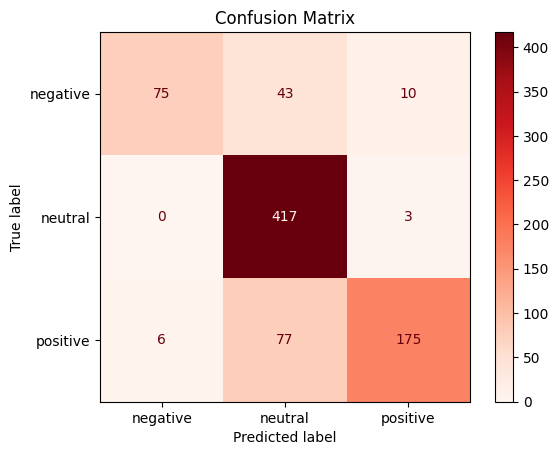

In [ ]:
class_names = ["negative", "neutral", "positive"]

disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred), display_labels=class_names)
disp.plot(cmap='Reds', values_format='d')
plt.title('Confusion Matrix')
plt.show()

# Visualisasi Data

In [ ]:
import pandas as pd

In [ ]:
vdata = pd.read_csv('/content/drive/MyDrive/capstone mikti/combine code/dataset/final_dataset.csv')
vdata.head()

,month,clean_full_text,tokens,topic,sentiment
0,desember,kiper vietnam puji main muda timnas indonesia ...,"['kiper', 'vietnam', 'puji', 'main', 'muda', '...",Kualifikasi Piala Dunia,Positif
1,desember,piala aff pssi sanjung tampil timnas indonesia...,"['piala', 'aff', 'pssi', 'sanjung', 'tampil', ...",Kualifikasi Piala Dunia,Netral
2,desember,kerepot tahan imbang laos ajar timnas indonesi...,"['kerepot', 'tahan', 'imbang', 'laos', 'ajar',...",Kualifikasi Piala Dunia,Netral
3,desember,susun main timnas indonesia laos struick start...,"['susun', 'main', 'timnas', 'indonesia', 'laos...",Manajemen Tim dan Pelatihan,Positif
4,desember,kalah vietnam pede indonesia semifinal timnas ...,"['kalah', 'vietnam', 'pede', 'indonesia', 'sem...",Kualifikasi Piala Dunia,Netral


In [ ]:
vdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5369 entries, 0 to 5368
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   month            5369 non-null   object
 1   clean_full_text  5369 non-null   object
 2   tokens           5369 non-null   object
 3   topic            5369 non-null   object
 4   sentiment        5369 non-null   object
dtypes: object(5)
memory usage: 209.9+ KB


### Visualisasi Bulan dengan berita terbanyak

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Group by month and count the number of news articles
month_counts = vdata.groupby('month')['clean_full_text'].count().sort_values(ascending=False)

# Display the results
print("News Count per Month:")
month_counts

News Count per Month:


,clean_full_text
month,
november,981
oktober,811
september,610
april,410
desember,399
mei,397
juli,370
juni,356
agustus,341


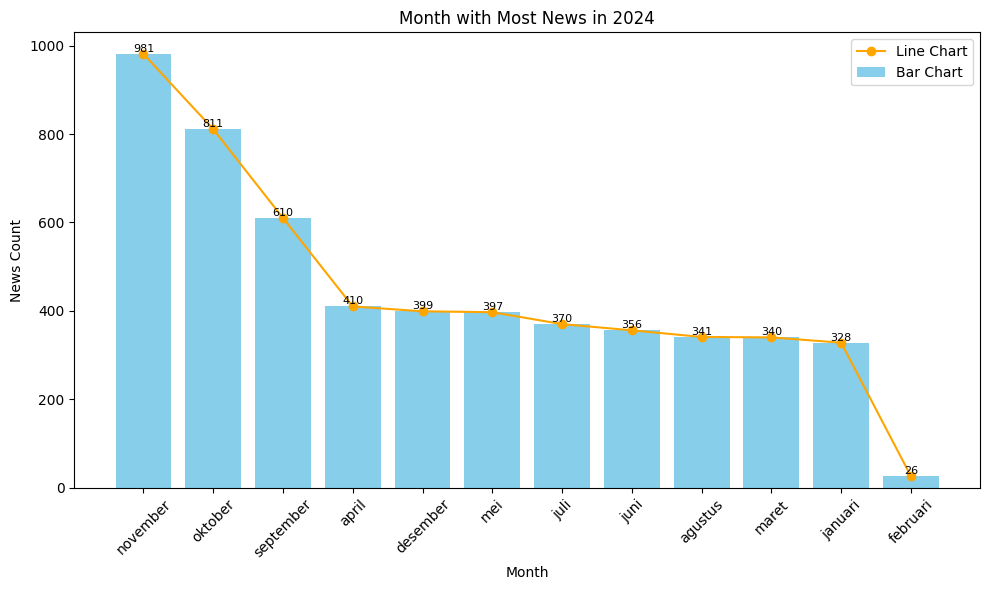

In [ ]:
# Bar chart & Line Chart
# Create a figure and an axes object
fig, ax1 = plt.subplots(figsize=(10, 6))

# Create the bar chart
bars = ax1.bar(month_counts.index, month_counts.values, color='skyblue', label='Bar Chart')  # Use a single color or a list of colors

# Create the line chart
ax1.plot(month_counts.index, month_counts.values, marker='o', linestyle='-', color='orange', label='Line Chart')

# Labeling
ax1.set_xlabel('Month')
ax1.set_ylabel('News Count')
ax1.set_title('Month with Most News in 2024')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

# Add labels to the bars
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval, round(yval, 2), ha='center', va='bottom', fontsize=8)

# Display the plot
plt.legend()
plt.tight_layout()
plt.show()

### Jumlah berita setiap bulannya

In [ ]:
# Group by month and count the number of news articles
month_count_news = vdata.groupby('month')['clean_full_text'].count()

# Define the desired month order
month_order = ['januari', 'februari', 'maret', 'april', 'mei', 'juni',
               'juli', 'agustus', 'september', 'oktober', 'november', 'desember']

# Convert 'month' to categorical with the specified order
month_count_news.index = pd.CategoricalIndex(month_count_news.index, categories=month_order, ordered=True)

# Sort the Series by the categorical index
month_count_news = month_count_news.sort_index()

# Display the results
print("News Count per Month:")
month_count_news

News Count per Month:


,clean_full_text
month,
januari,328
februari,26
maret,340
april,410
mei,397
juni,356
juli,370
agustus,341
september,610


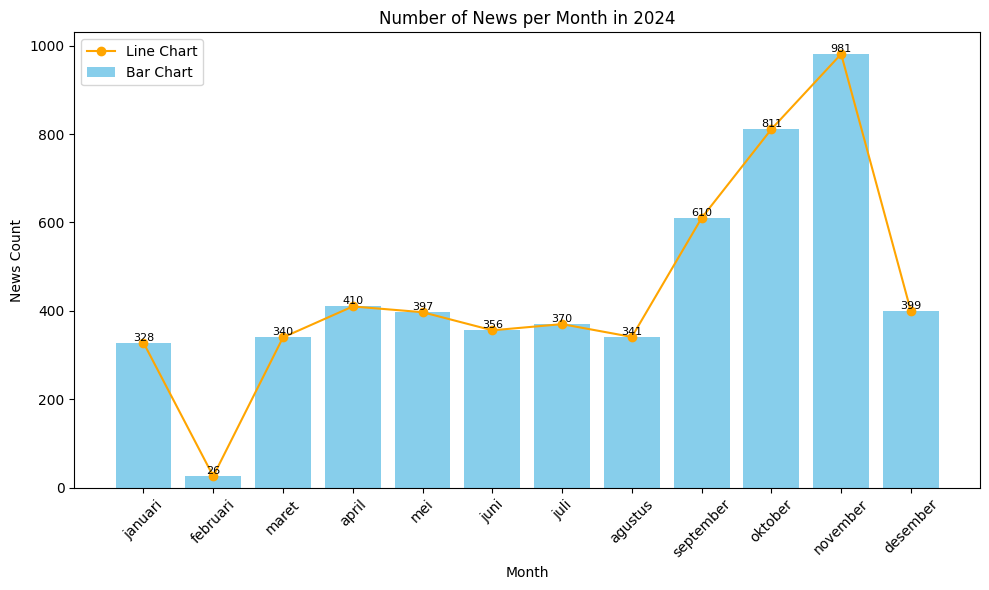

In [ ]:
#Bar chart & Line Chart
# Create a figure and an axes object
fig, ax1 = plt.subplots(figsize=(10, 6))

# Create the bar chart
bars = plt.bar(month_count_news.index, month_count_news.values, color='skyblue', label='Bar Chart')

# Create the line chart
plt.plot(month_count_news.index, month_count_news.values, marker='o', linestyle='-',color='orange', label='Line Chart')

# Labeling
plt.xlabel('Month')
plt.ylabel('News Count')
plt.title('Number of News per Month in 2024')

#Rotate
plt.xticks(rotation=45)

# Add labels to the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval, round(yval, 2), ha='center', va='bottom', fontsize=8)

# Display the plot
plt.legend()
plt.tight_layout()
plt.show()

### Visualisasi rata-rata & jumlah panjang berita setiap bulan

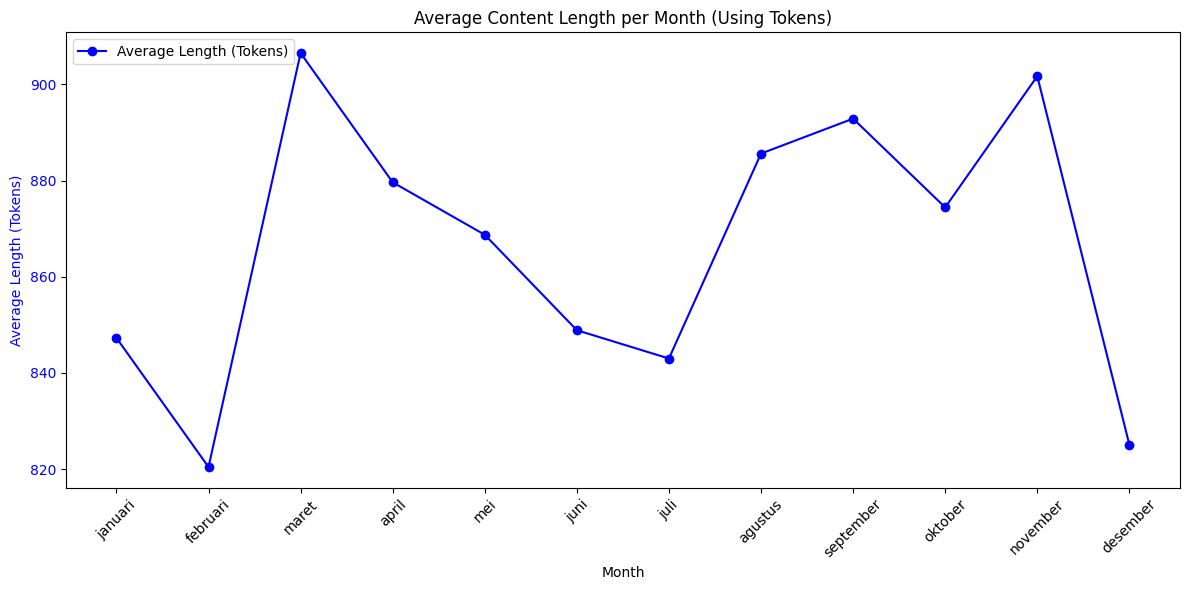

,avg_length
month,
januari,847.295732
februari,820.461538
maret,906.494118
april,879.631707
mei,868.725441
juni,848.890449
juli,843.010811
agustus,885.601173
september,892.857377


In [ ]:
# Calculate average title and content length per month using tokens
average_lengths = vdata.groupby('month').agg(
    {'tokens': lambda x: x.str.len().mean()}  # Calculate mean of string lengths (tokens)
).rename(columns={'tokens': 'avg_length'})

# Define the desired month order
month_order = ['januari', 'februari', 'maret', 'april', 'mei', 'juni',
               'juli', 'agustus', 'september', 'oktober', 'november', 'desember']

# Convert the index to categorical with the specified order
average_lengths.index = pd.CategoricalIndex(average_lengths.index, categories=month_order, ordered=True)

# Sort the DataFrame by the categorical index
average_lengths = average_lengths.sort_index()

# Plotting
fig, ax = plt.subplots(figsize=(12, 6))  # Use a single axes object

# Line chart for average length (tokens)
ax.plot(average_lengths.index, average_lengths['avg_length'], marker='o', linestyle='-', color='blue', label='Average Length (Tokens)')
ax.set_xlabel('Month')
ax.set_ylabel('Average Length (Tokens)', color='blue')
ax.tick_params(axis='y', labelcolor='blue')

# Customize the plot
plt.title('Average Content Length per Month (Using Tokens)')
plt.xticks(rotation=45)
plt.tight_layout()

# Display the legend
plt.legend(loc='upper left')
plt.show()

# Display the average lengths DataFrame
average_lengths

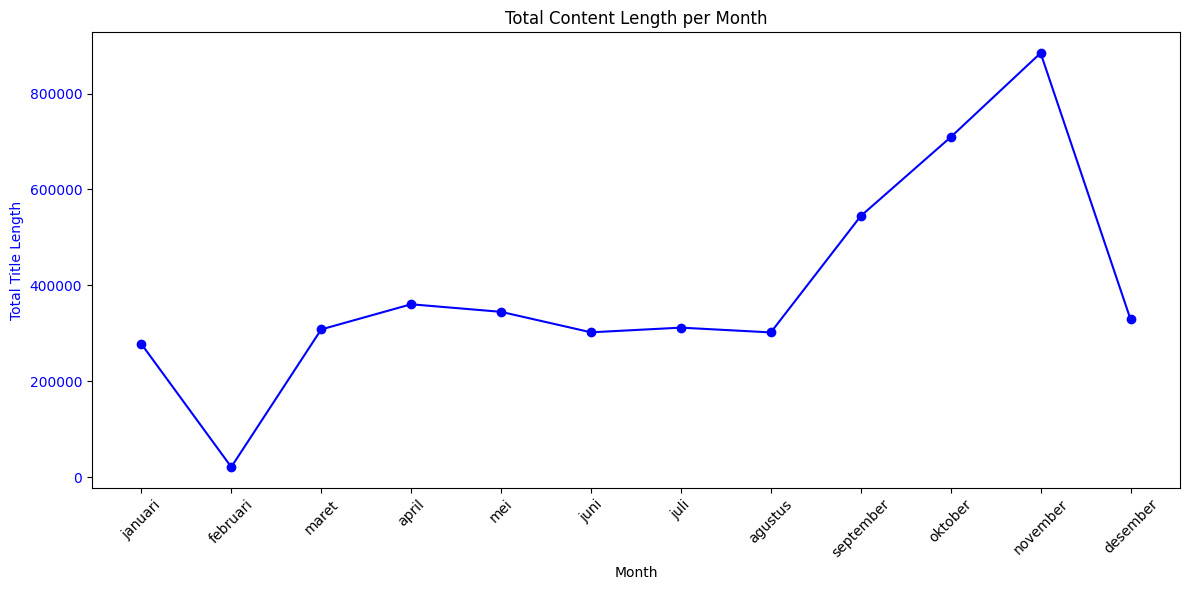

,total_length
month,
januari,277913
februari,21332
maret,308208
april,360649
mei,344884
juni,302205
juli,311914
agustus,301990
september,544643


In [ ]:
# Calculate total title and content length per month
total_lengths = vdata.groupby('month').agg(
    {'tokens': lambda x: x.str.len().sum()}  # Calculate sum of string lengths
).rename(columns={'tokens': 'total_length'})

# Define the desired month order
month_order = ['januari', 'februari', 'maret', 'april', 'mei', 'juni',
               'juli', 'agustus', 'september', 'oktober', 'november', 'desember']

# Convert the index to categorical with the specified order
total_lengths.index = pd.CategoricalIndex(total_lengths.index, categories=month_order, ordered=True)

# Sort the DataFrame by the categorical index
total_lengths = total_lengths.sort_index()

# Plotting
fig, ax1 = plt.subplots(figsize=(12, 6))

# Line chart for total title length
line1, = ax1.plot(total_lengths.index, total_lengths['total_length'], marker='o', linestyle='-', color='blue', label='Total Title Length')  # Assign line to line1
ax1.set_xlabel('Month')
ax1.set_ylabel('Total Title Length', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Customize the plot
plt.title('Total Content Length per Month')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display the total lengths DataFrame
total_lengths

### Visualisasi Perkembangan Sentimen Setiap Bulannya

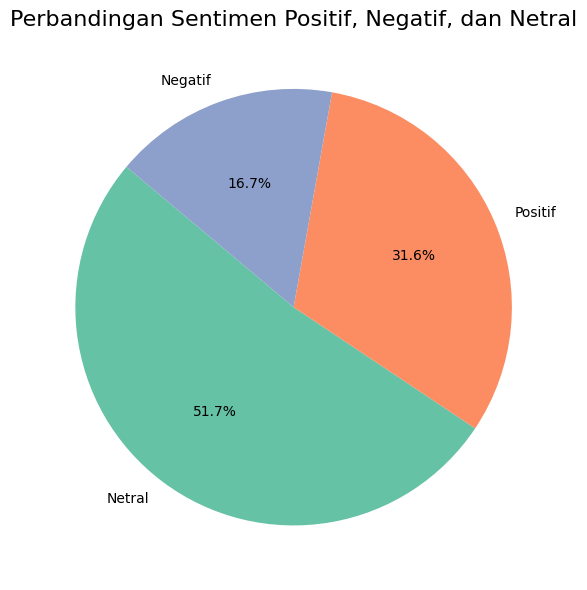

In [ ]:
# Count sentiment occurrences
sentiment_summary = vdata['sentiment'].value_counts()

# Plot the comparison of positive, negative, and neutral sentiment
plt.figure(figsize=(8, 6))
sentiment_summary.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=140,
    colors=['#66c2a5', '#fc8d62', '#8da0cb'],
    ylabel=''
)
plt.title('Perbandingan Sentimen Positif, Negatif, dan Netral', fontsize=16)
plt.tight_layout()
plt.show()

/tmp/ipython-input-3017999231.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['month'] = filtered_data['month'].str.capitalize()


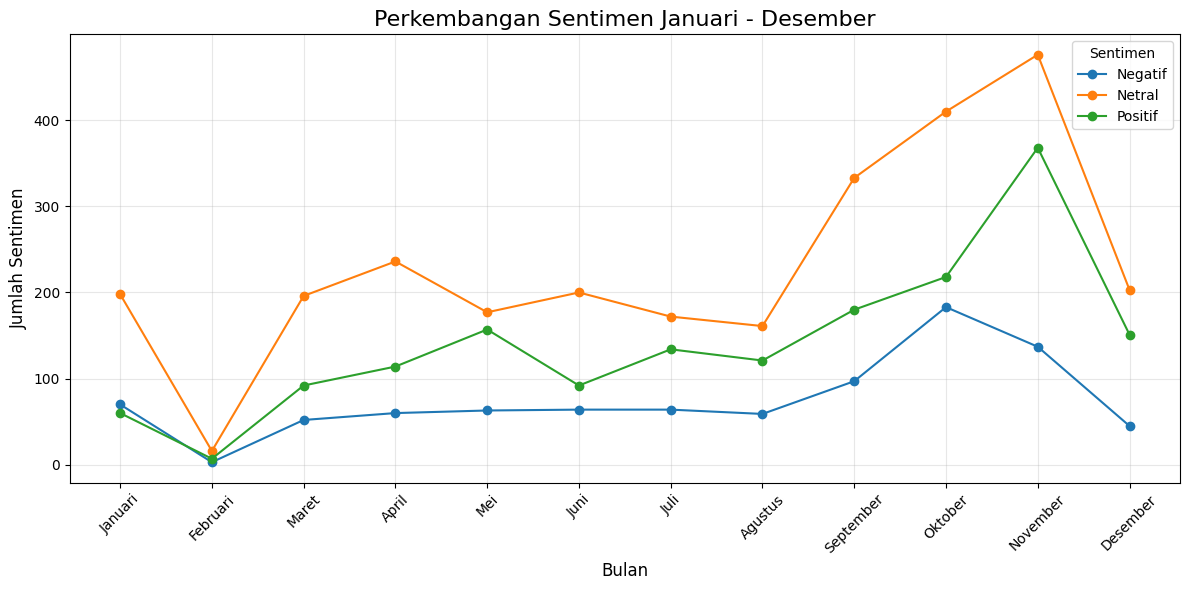

In [ ]:
import matplotlib.pyplot as plt

# Filter relevant columns
filtered_data = vdata[['month', 'sentiment']]

# Standardize month names to proper casing
filtered_data['month'] = filtered_data['month'].str.capitalize()

# Define month order
month_order = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni',
               'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']

# Group by month and sentiment, count occurrences
sentiment_counts = (
    filtered_data.groupby(['month', 'sentiment'])
    .size()
    .reset_index(name='count')
)

# Pivot data to get separate columns for each sentiment
pivot_sentiment = sentiment_counts.pivot(index='month', columns='sentiment', values='count').fillna(0)

# Reindex by month order
pivot_sentiment = pivot_sentiment.reindex(month_order)

# Plot the data
plt.figure(figsize=(12, 6))
for sentiment in pivot_sentiment.columns:
    plt.plot(pivot_sentiment.index, pivot_sentiment[sentiment], label=sentiment, marker='o')

# Add labels, title, and legend
plt.title('Perkembangan Sentimen Januari - Desember', fontsize=16)
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Jumlah Sentimen', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Sentimen')
plt.grid(alpha=0.3)
plt.tight_layout()

# Show plot
plt.show()

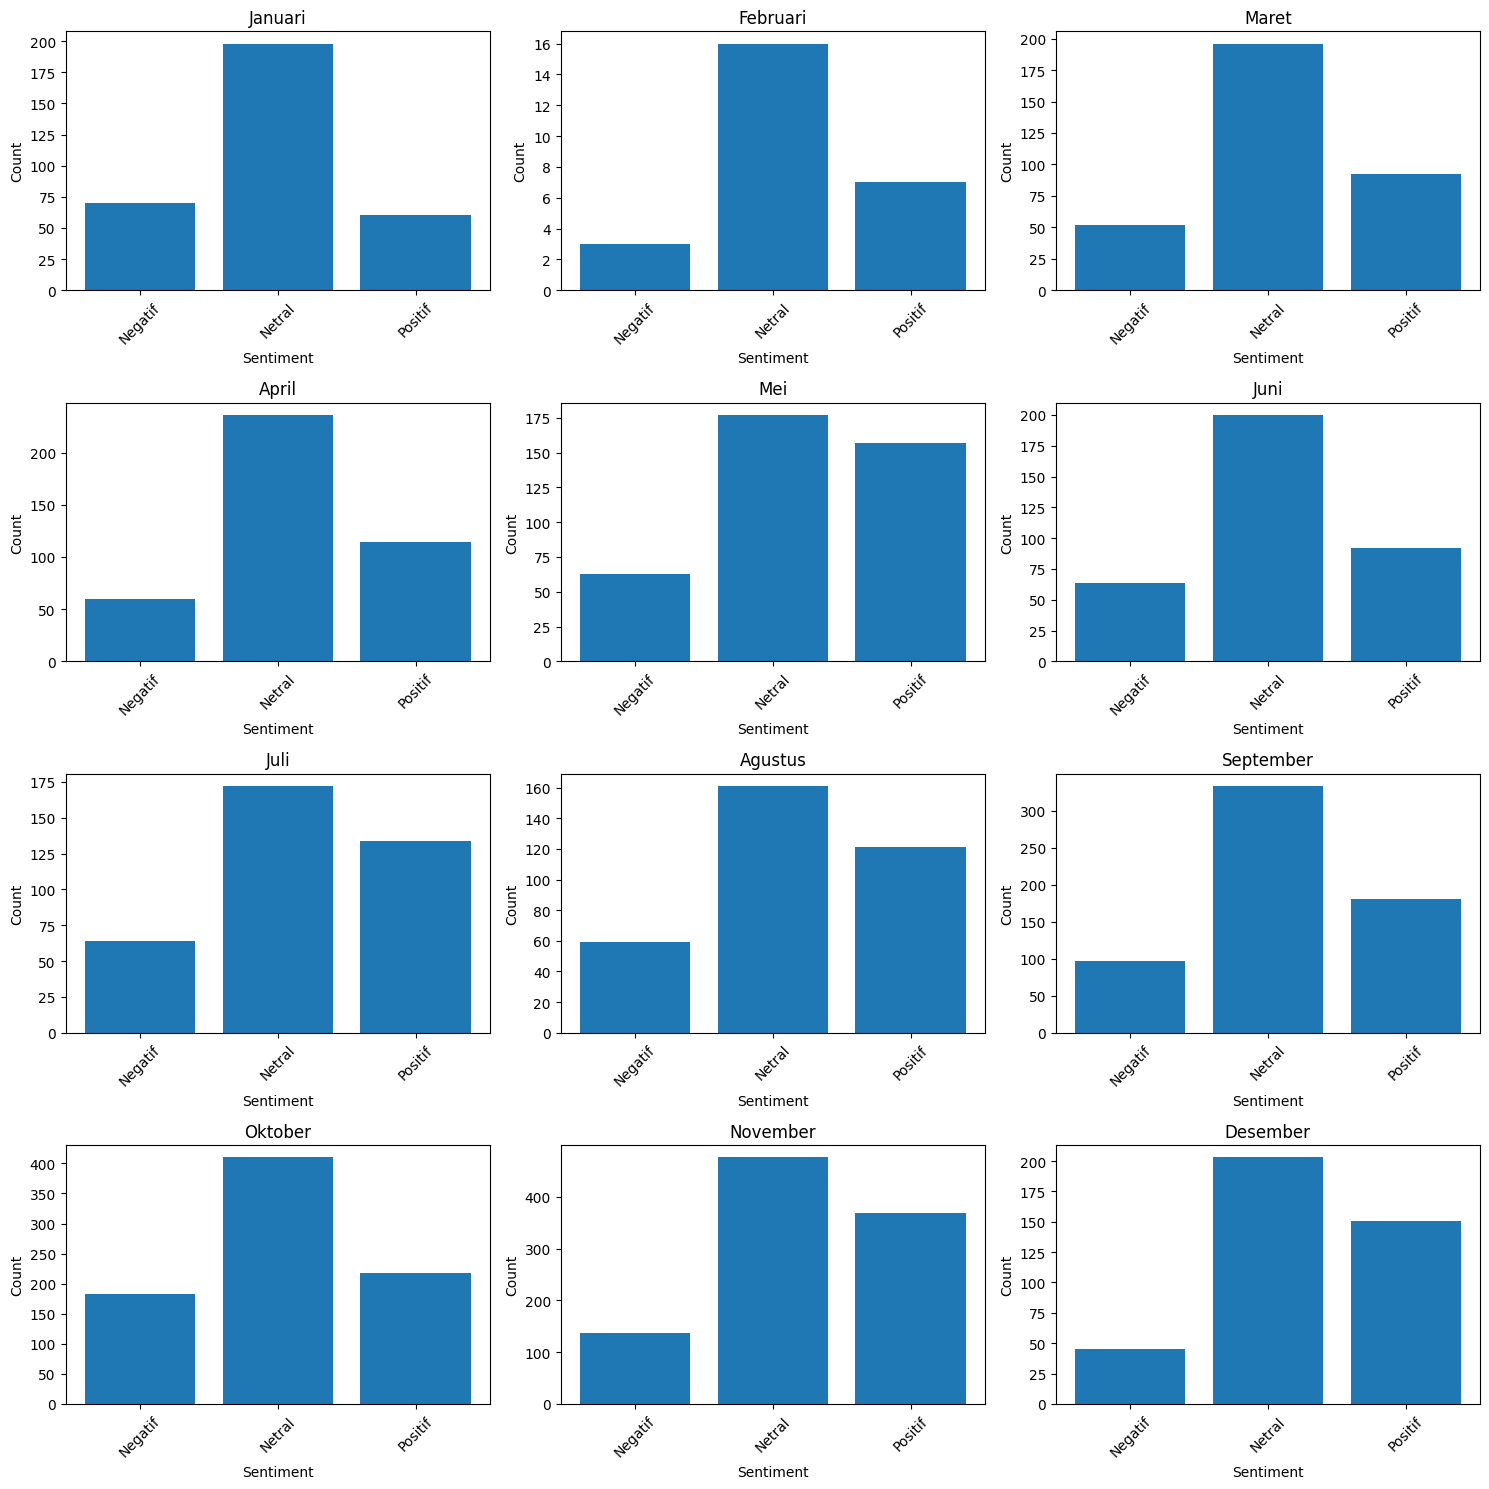

In [ ]:
import matplotlib.pyplot as plt

# Create subplots for better visualization
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 15))
axes = axes.flatten()  # Flatten the array for easier iteration

# Iterate through each month
for i, month in enumerate(pivot_sentiment.index):
    ax = axes[i]
    data = pivot_sentiment.loc[month]

    # Create a bar chart for each sentiment in the current month
    ax.bar(data.index, data.values)
    ax.set_title(month)
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

# Remove any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Visualisasi Perbandingan Sentiment Positif vs Negatif

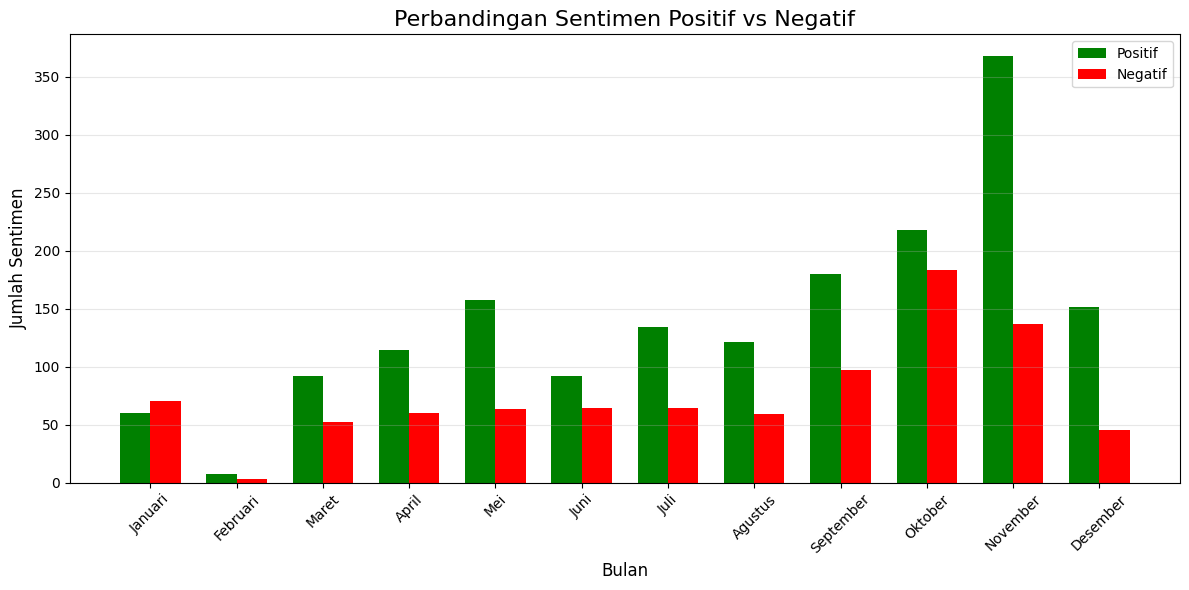

In [ ]:
import numpy as np

# Create a bar chart comparing positive and negative sentiments for each month
plt.figure(figsize=(12, 6))
width = 0.35  # Width of the bars

# Ensure 'Positif' and 'Negatif' columns exist in pivot_sentiment
if 'Positif' in pivot_sentiment.columns and 'Negatif' in pivot_sentiment.columns:
    positive_sentiments = pivot_sentiment['Positif']
    negative_sentiments = pivot_sentiment['Negatif']

    x = np.arange(len(pivot_sentiment.index))  # Location for the bars

    # Create bars for positive and negative sentiments
    plt.bar(x - width/2, positive_sentiments, width, label='Positif', color='green')
    plt.bar(x + width/2, negative_sentiments, width, label='Negatif', color='red')

    # Add labels and title
    plt.xlabel('Bulan', fontsize=12)
    plt.ylabel('Jumlah Sentimen', fontsize=12)
    plt.title('Perbandingan Sentimen Positif vs Negatif', fontsize=16)
    plt.xticks(x, pivot_sentiment.index, rotation=45)  # Set x-axis ticks to month names
    plt.legend()
    plt.tight_layout()
    plt.grid(axis='y', alpha=0.3)

    # Display the plot
    plt.show()
else:
    print("Kolom 'Positif' atau 'Negatif' tidak ditemukan dalam data pivot_sentiment.")

### Visualisasi Pembahasan Topik Setiap Bulannya

---



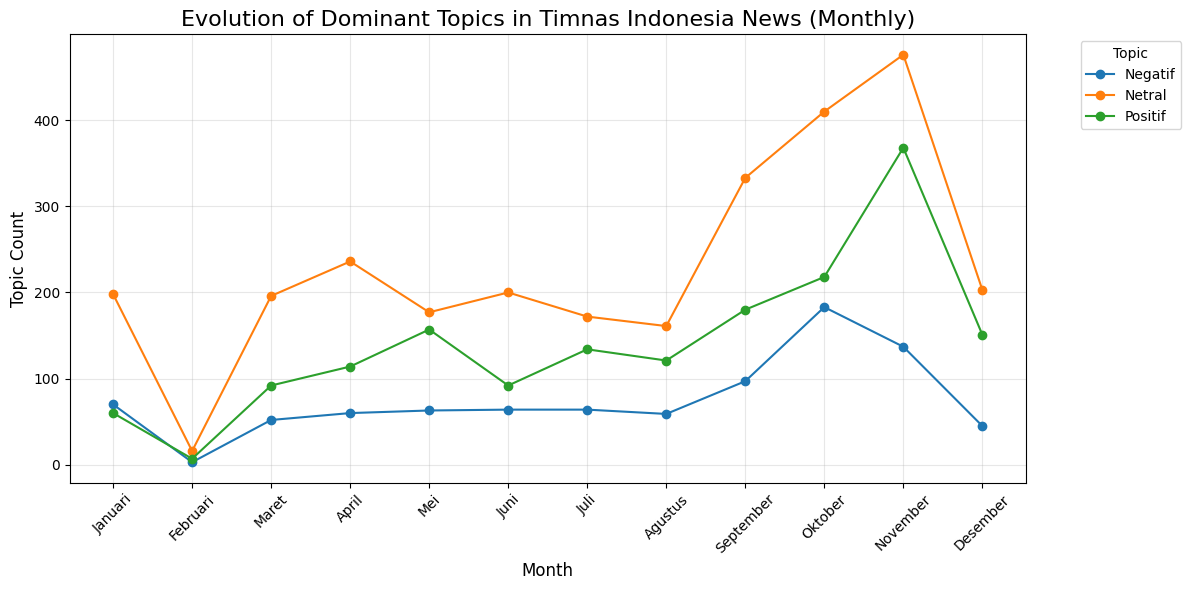

In [ ]:
plt.figure(figsize=(12, 6))
for topic in pivot_sentiment.columns:
    plt.plot(pivot_sentiment.index, pivot_sentiment[topic], label=topic, marker='o')

plt.title('Evolution of Dominant Topics in Timnas Indonesia News (Monthly)', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Topic Count', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Topic', bbox_to_anchor=(1.05, 1), loc='upper left') # Improved legend placement
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipython-input-3245408665.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['month'] = filtered_data['month'].str.capitalize()
/tmp/ipython-input-3245408665.py:28: MatplotlibDeprecationWarning: Passing label as a length 2 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot(pivot_sentiment.index, pivot_sentiment[sentiment], label=sentiment, marker='o')


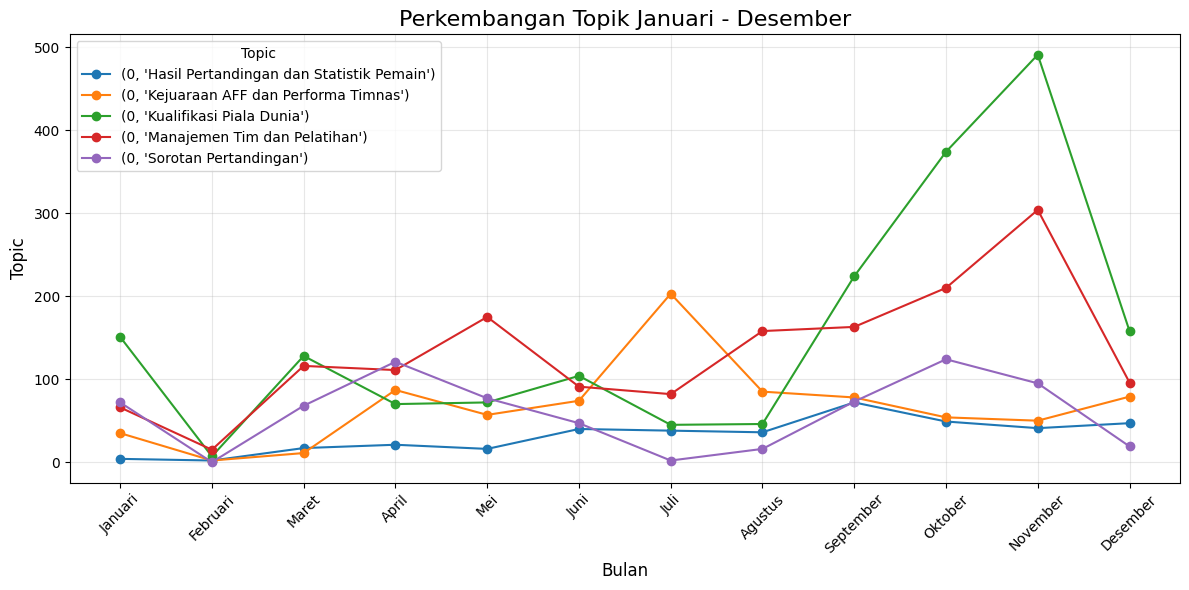

In [ ]:
import matplotlib.pyplot as plt

# Filter relevant columns
filtered_data = vdata[['month', 'topic']]

# Standardize month names to proper casing
filtered_data['month'] = filtered_data['month'].str.capitalize()

# Define month order
month_order = ['Januari', 'Februari', 'Maret', 'April', 'Mei', 'Juni',
               'Juli', 'Agustus', 'September', 'Oktober', 'November', 'Desember']

# Group by month and sentiment, count occurrences
sentiment_counts = (
    filtered_data.groupby(['month', 'topic'])
    .size()
)

# Pivot data to get separate columns for each sentiment
pivot_sentiment = sentiment_counts.reset_index().pivot(index='month', columns='topic').fillna(0)

# Reindex by month order
pivot_sentiment = pivot_sentiment.reindex(month_order)

# Plot the data
plt.figure(figsize=(12, 6))
for sentiment in pivot_sentiment.columns:
    plt.plot(pivot_sentiment.index, pivot_sentiment[sentiment], label=sentiment, marker='o')

# Add labels, title, and legend
plt.title('Perkembangan Topik Januari - Desember', fontsize=16)
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Topic', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Topic')
plt.grid(alpha=0.3)
plt.tight_layout()

# Show plot
plt.show()

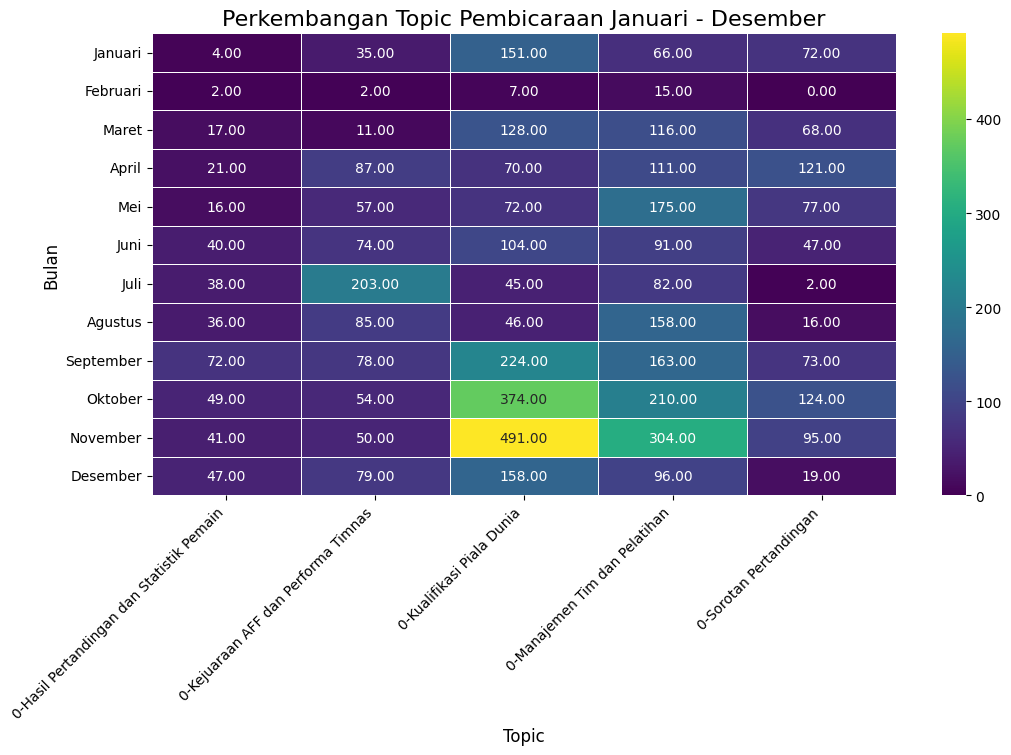

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create the heatmap using seaborn
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_sentiment, annot=True, fmt=".2f", cmap="viridis", linewidths=.5)

# Add labels and title
plt.title('Perkembangan Topic Pembicaraan Januari - Desember', fontsize=16)
plt.xlabel('Topic', fontsize=12)
plt.ylabel('Bulan', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Show plot
plt.show()

### Visualisasi Tren Kata Dominan per Bulan

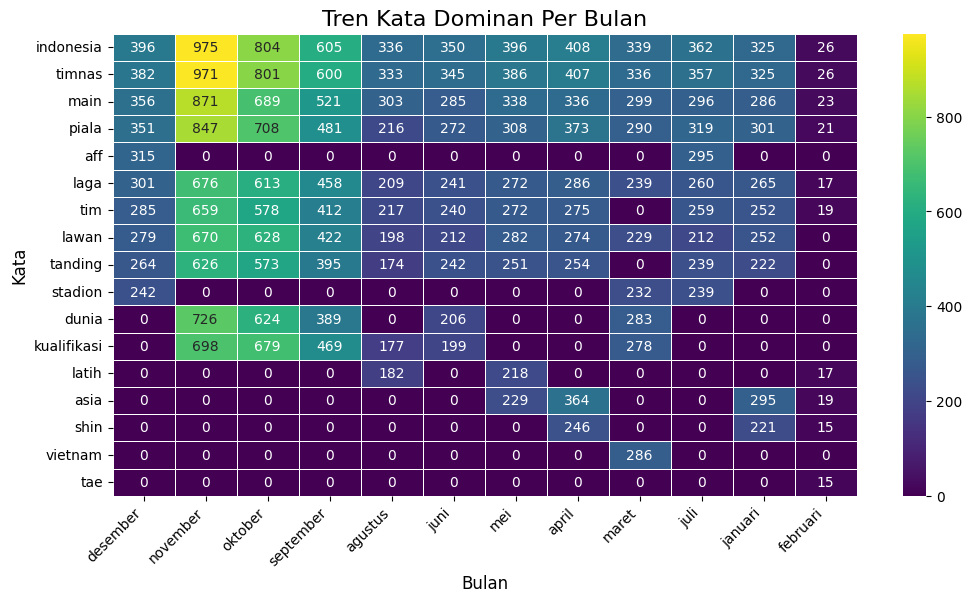

In [ ]:
def count_dominant_words(df, month, top_n=10):
    """Counts the dominant words for a given month."""

    month_data = vdata[vdata['month'] == month]
    all_words = []
    for tokens in month_data['tokens']:
      if isinstance(tokens, str):  # Check if tokens is a string
        try:
            all_words.extend(eval(tokens))  # Safely evaluate string representation of the list
        except (NameError, SyntaxError):
            print(f"Skipping invalid 'tokens' value: {tokens}")
            continue  # Skip to the next iteration

    word_counts = {}
    for word in all_words:
      word_counts[word] = word_counts.get(word, 0) + 1

    sorted_word_counts = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)

    return dict(sorted_word_counts[:top_n])

# Create a dictionary to store dominant words for each month
dominant_words_per_month = {}

for month in vdata['month'].unique():
    dominant_words_per_month[month] = count_dominant_words(vdata, month)


# Convert dominant_words_per_month to a DataFrame for easier visualization
dominant_words_vdata = pd.DataFrame(dominant_words_per_month).fillna(0).astype(int)


# Plot the heatmap using seaborn
plt.figure(figsize=(12, 6))
sns.heatmap(dominant_words_vdata, annot=True, fmt="d", cmap="viridis", linewidths=.5)

# Add labels and title
plt.title('Tren Kata Dominan Per Bulan', fontsize=16)
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Kata', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Show plot
plt.show()

### Most Highlight Topic

In [ ]:
def count_dominant_words(vdata, month, top_n=10):
    """Counts the dominant words for a given month."""

    month_data = vdata[vdata['month'] == month]
    all_words = []
    for tokens in month_data['tokens']:
      if isinstance(tokens, str):  # Check if tokens is a string
        try:
            all_words.extend(eval(tokens))  # Safely evaluate string representation of the list
        except (NameError, SyntaxError):
            print(f"Skipping invalid 'tokens' value: {tokens}")
            continue  # Skip to the next iteration

    word_counts = {}
    for word in all_words:
      word_counts[word] = word_counts.get(word, 0) + 1

    sorted_word_counts = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)

    return dict(sorted_word_counts[:top_n])

# Analyze dominant words per month
dominant_words_per_month = {}
for month in vdata['month'].unique():
    dominant_words_per_month[month] = count_dominant_words(vdata, month)

# Convert to DataFrame
dominant_words_vdata = pd.DataFrame(dominant_words_per_month).fillna(0).astype(int)

# Count occurrences of each topic across all months
topic_counts = vdata['topic'].value_counts()
top_topics = topic_counts.head(5)

# Print the results: These are the most highlighted topics in the news.
print("\nMost Highlighted Topics (Overall):")
top_topics


Most Highlighted Topics (Overall):


,count
topic,
Kualifikasi Piala Dunia,1870
Manajemen Tim dan Pelatihan,1587
Kejuaraan AFF dan Performa Timnas,815
Sorotan Pertandingan,714
Hasil Pertandingan dan Statistik Pemain,383


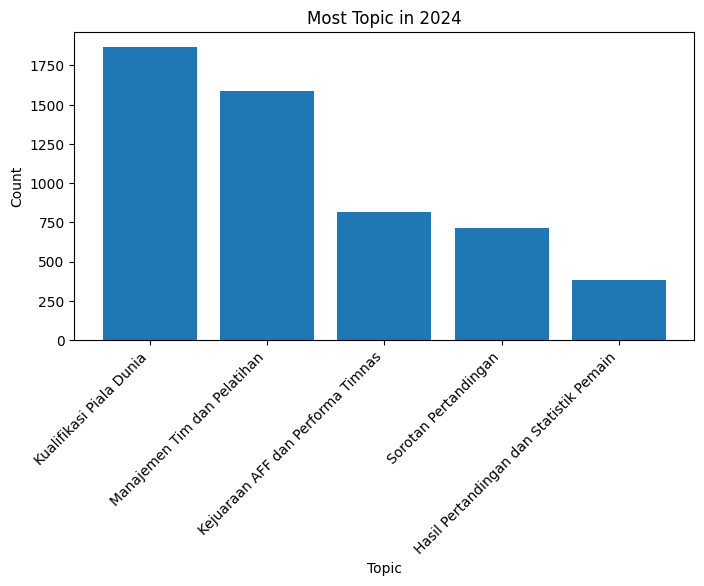

In [ ]:
import matplotlib.pyplot as plt

# Calculate the topic label counts
topic_label_count = vdata['topic'].value_counts()

#Visualisation Month with the most news
plt.figure(figsize=(8, 4))  # Mengatur ukuran gambar
plt.bar(topic_label_count.index, topic_label_count.values) # Use .index and .values
plt.title('Most Topic in 2024')
plt.xlabel('Topic')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')  # Memutar label sumbu x dengan arah 45 derajat
plt.show()

### Distribusi sentiment berdasarkan topic

In [ ]:
import pandas as pd

def analyze_sentiment_by_topic(vdata):
    """
    Analyzes the overall sentiment associated with each major topic category.

    Args:
        vdata: pandas DataFrame containing 'topic' and 'sentiment' columns.

    Returns:
        pandas DataFrame: A table summarizing the overall sentiment for each topic.
    """
    # Group by topic and sentiment, count occurrences
    topic_sentiment_counts = vdata.groupby(['topic', 'sentiment']).size().unstack(fill_value=0)

    # Calculate the overall sentiment for each topic
    topic_sentiment_counts['Total'] = topic_sentiment_counts.sum(axis=1)
    topic_sentiment_counts['Positive Ratio'] = topic_sentiment_counts['Positif'] / topic_sentiment_counts['Total']
    topic_sentiment_counts['Negative Ratio'] = topic_sentiment_counts['Negatif'] / topic_sentiment_counts['Total']
    topic_sentiment_counts['Neutral Ratio'] = topic_sentiment_counts['Netral'] / topic_sentiment_counts['Total']

    # Determine the overall sentiment label based on the highest ratio
    topic_sentiment_counts['Overall Sentiment'] = topic_sentiment_counts[['Positive Ratio', 'Negative Ratio', 'Neutral Ratio']].idxmax(axis=1)
    topic_sentiment_counts['Overall Sentiment'] = topic_sentiment_counts['Overall Sentiment'].str.replace(' Ratio', '')

    return topic_sentiment_counts

sentiment_analysis_result = analyze_sentiment_by_topic(vdata)
sentiment_analysis_result

sentiment,Negatif,Netral,Positif,Total,Positive Ratio,Negative Ratio,Neutral Ratio,Overall Sentiment
topic,,,,,,,,
Hasil Pertandingan dan Statistik Pemain,69,150,164,383,0.428198,0.180157,0.391645,Positive
Kejuaraan AFF dan Performa Timnas,98,445,272,815,0.333742,0.120245,0.546012,Neutral
Kualifikasi Piala Dunia,307,1125,438,1870,0.234225,0.164171,0.601604,Neutral
Manajemen Tim dan Pelatihan,283,694,610,1587,0.384373,0.178324,0.437303,Neutral
Sorotan Pertandingan,140,364,210,714,0.294118,0.196078,0.509804,Neutral


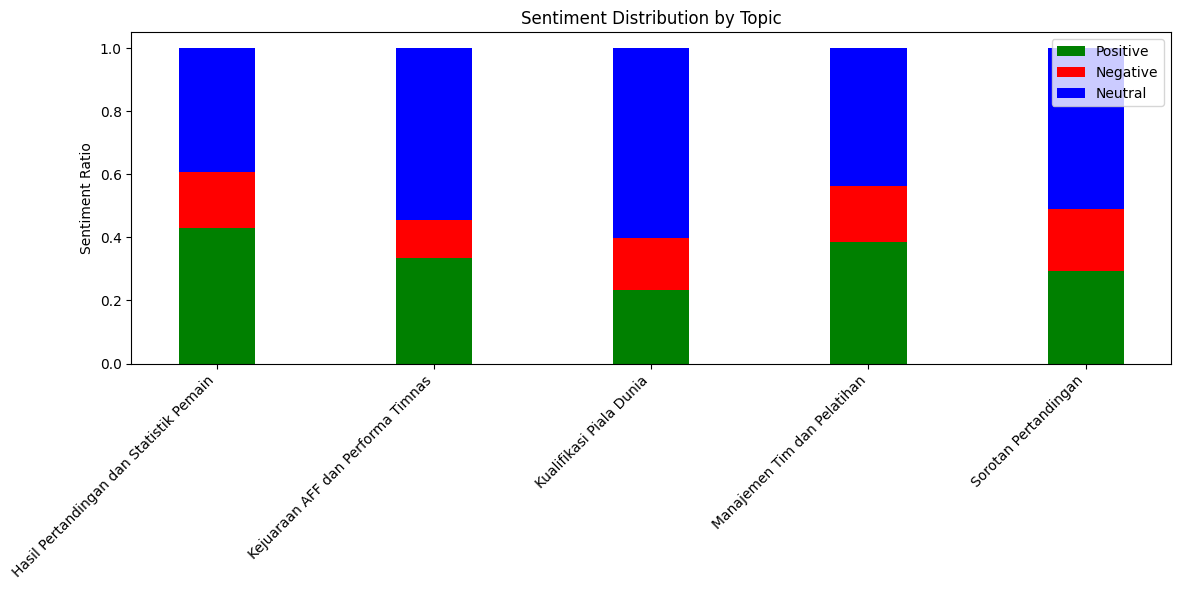

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get data for plotting
topics = sentiment_analysis_result.index
positive_ratios = sentiment_analysis_result['Positive Ratio']
negative_ratios = sentiment_analysis_result['Negative Ratio']
neutral_ratios = sentiment_analysis_result['Neutral Ratio']

# Create stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))
width = 0.35  # Width of the bars
x = np.arange(len(topics))

ax.bar(x, positive_ratios, width, label='Positive', color='green')
ax.bar(x, negative_ratios, width, bottom=positive_ratios, label='Negative', color='red')
ax.bar(x, neutral_ratios, width, bottom=positive_ratios + negative_ratios, label='Neutral', color='blue')

# Add labels and title
ax.set_ylabel('Sentiment Ratio')
ax.set_title('Sentiment Distribution by Topic')
ax.set_xticks(x)
ax.set_xticklabels(topics, rotation=45, ha='right')
ax.legend()

# Display plot
plt.tight_layout()
plt.show()

### wordcloud

Generating Word Cloud for Sentiment: Positif


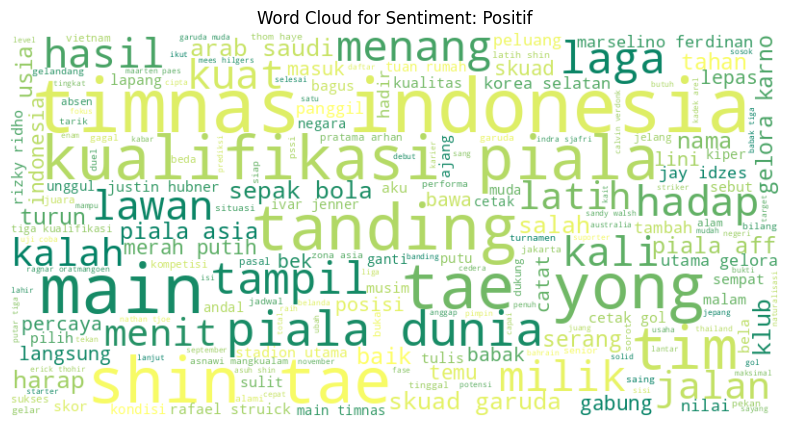

Generating Word Cloud for Sentiment: Negatif


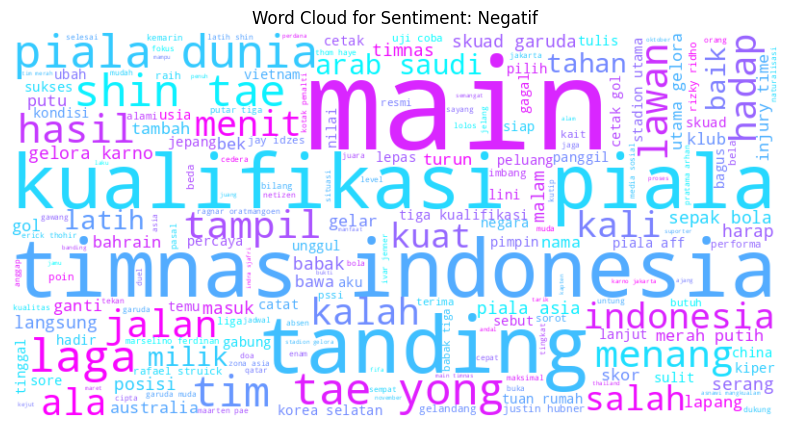

Generating Word Cloud for Sentiment: Netral


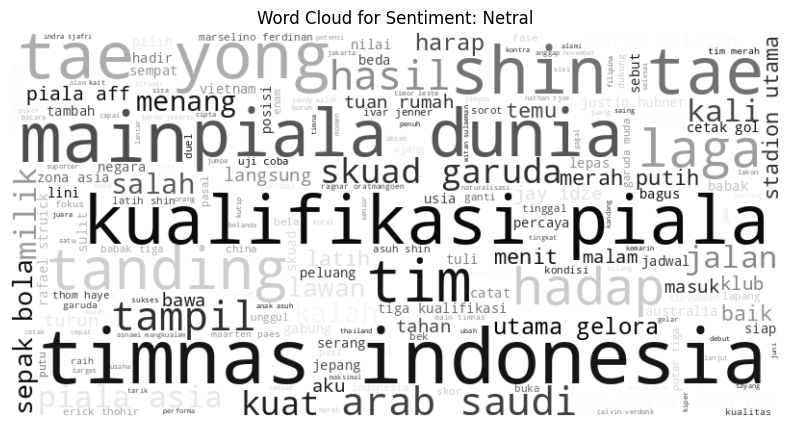

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Filter data by sentiment
def generate_wordcloud(vdata, sentiment, color_func=None):
    # Gabungkan semua teks berdasarkan sentimen
    text = " ".join(vdata[vdata['sentiment'] == sentiment]['clean_full_text'])
    # Buat WordCloud
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap=color_func
    ).generate(text)

    # Tampilkan WordCloud
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Sentiment: {sentiment}')
    plt.show()

# Generate WordCloud for Positif with warm color
print("Generating Word Cloud for Sentiment: Positif")
generate_wordcloud(vdata, "Positif", color_func="summer")

# Generate WordCloud for Negatif with dark color
print("Generating Word Cloud for Sentiment: Negatif")
generate_wordcloud(vdata, "Negatif", color_func="cool")

# Generate WordCloud for Netral with neutral color
print("Generating Word Cloud for Sentiment: Netral")
generate_wordcloud(vdata, "Netral", color_func="gray")



Word Cloud for Pemberitaan - Januari


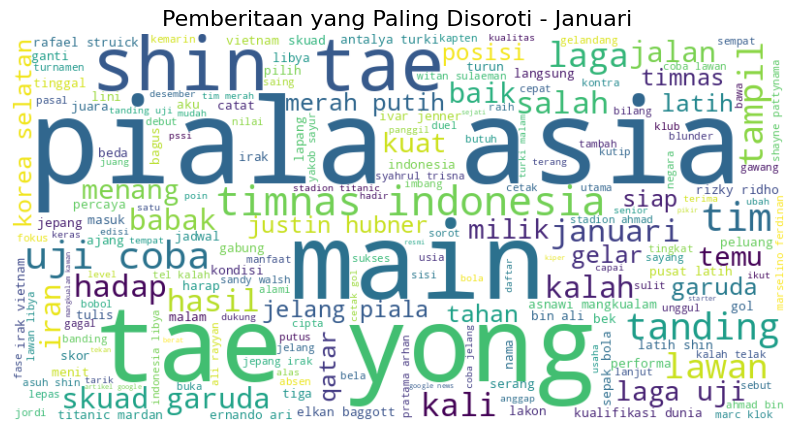


Word Cloud for Pemberitaan - Februari


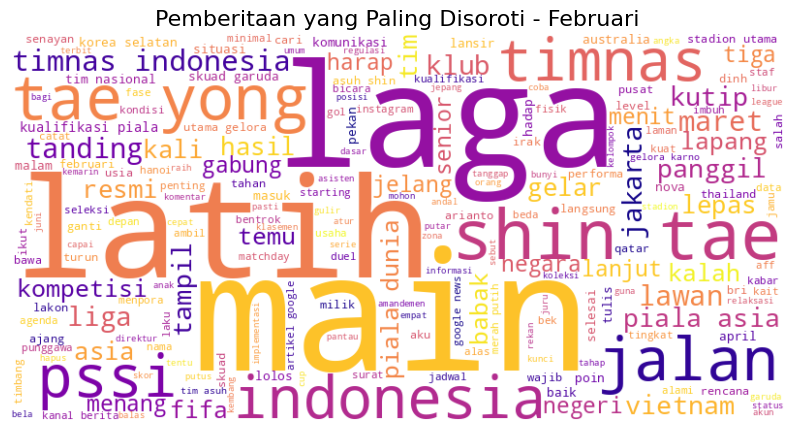


Word Cloud for Pemberitaan - Maret


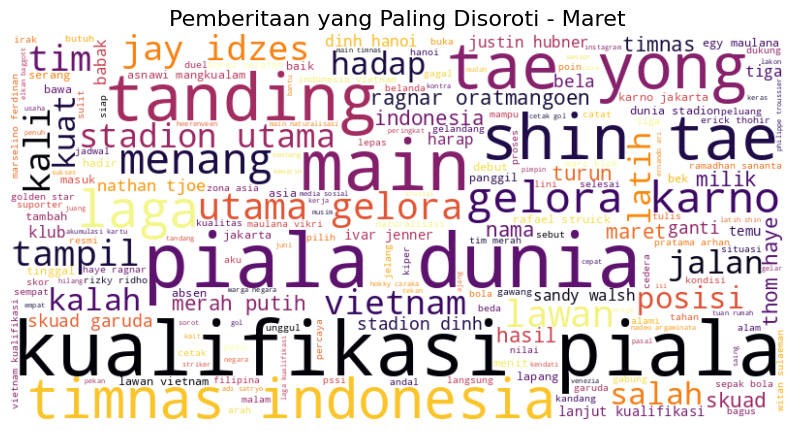


Word Cloud for Pemberitaan - April


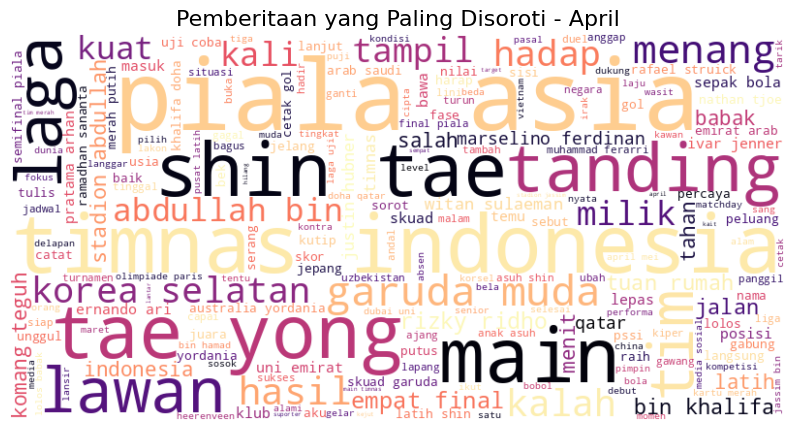


Word Cloud for Pemberitaan - Mei


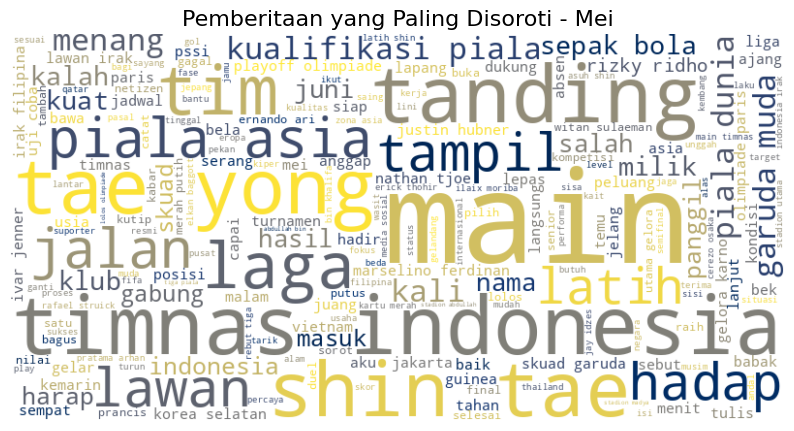


Word Cloud for Pemberitaan - Juni


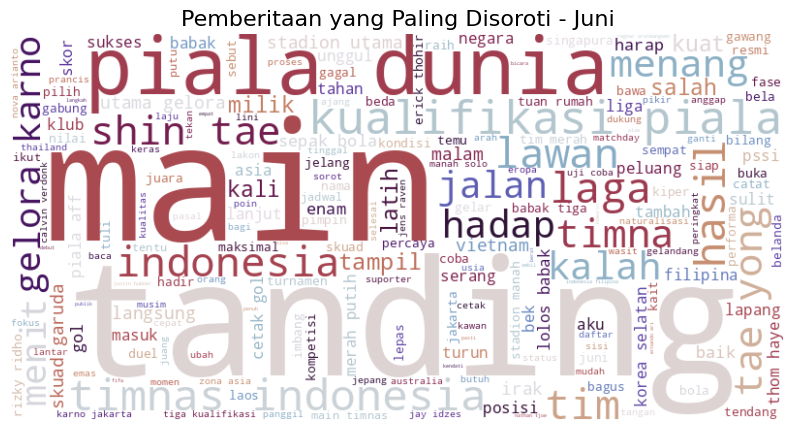


Word Cloud for Pemberitaan - Juli


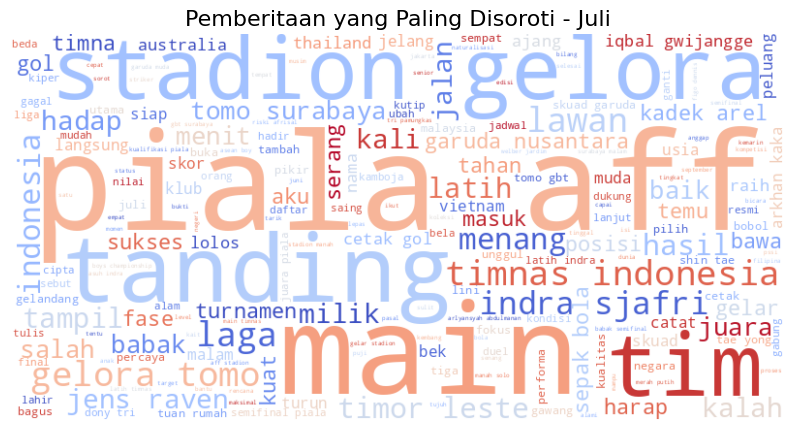


Word Cloud for Pemberitaan - Agustus


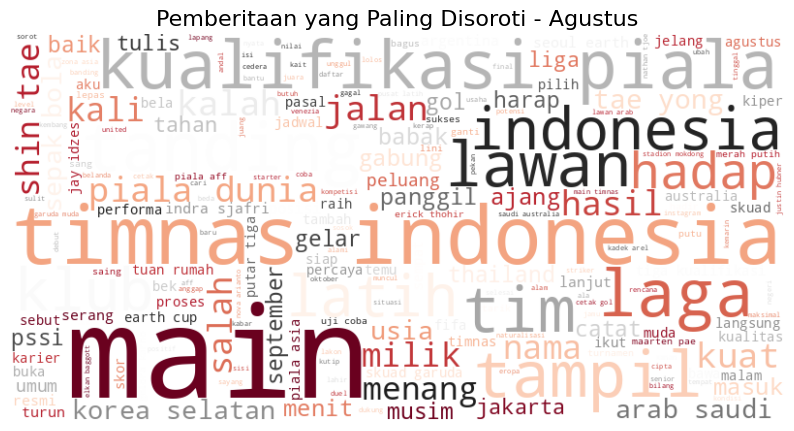


Word Cloud for Pemberitaan - September


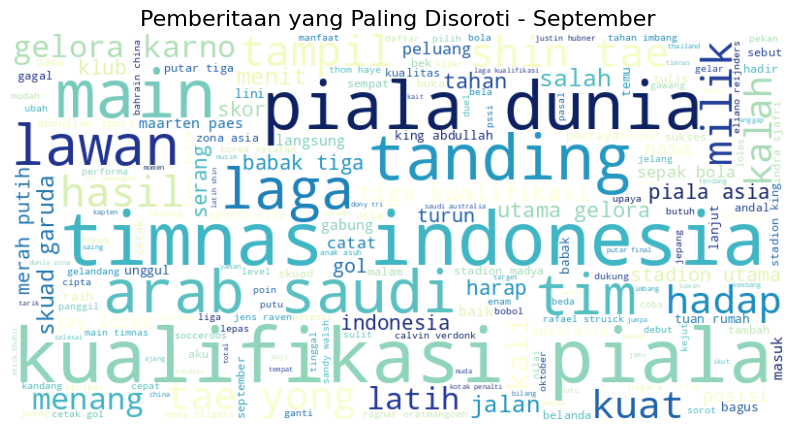


Word Cloud for Pemberitaan - Oktober


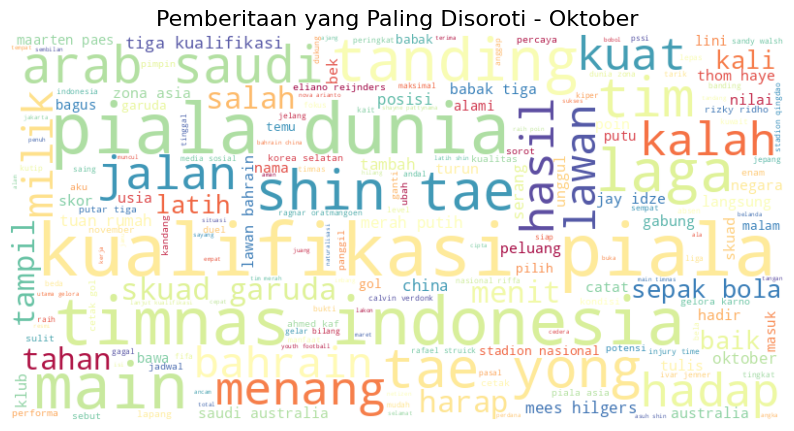


Word Cloud for Pemberitaan - November


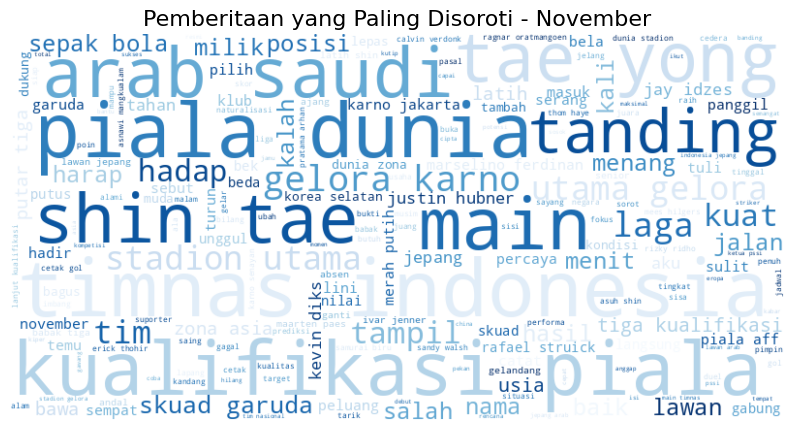


Word Cloud for Pemberitaan - Desember


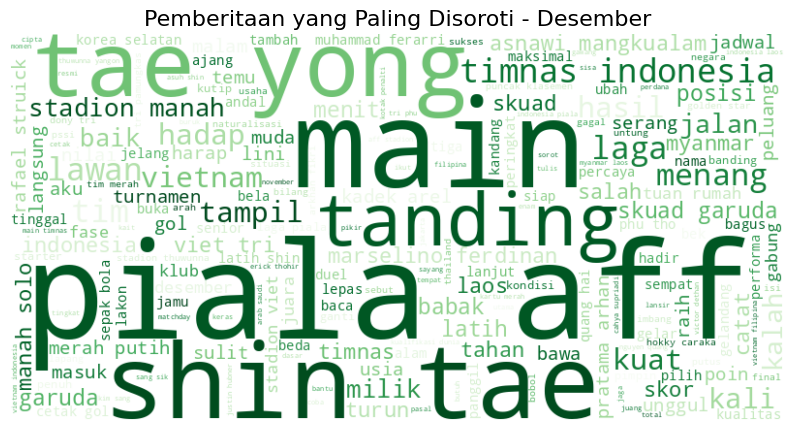

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Function to generate wordcloud for a specific month with different colors
def generate_wordcloud_per_month(vdata, month, title, colormap):
    # Gabungkan semua teks berdasarkan bulan
    text = " ".join(vdata[vdata['month'] == month]['clean_full_text'])
    if text.strip():  # Hanya buat wordcloud jika teks tidak kosong
        # Generate word cloud
        wordcloud = WordCloud(width=800, height=400, background_color='white', colormap=colormap).generate(text)
        # Plot word cloud
        plt.figure(figsize=(10, 6))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis("off")
        plt.title(f"{title} - {month.capitalize()}", fontsize=16)
        plt.show()
    else:
        print(f"Tidak ada data untuk {title} - {month.capitalize()}")

# Define the list of months
months = ['januari', 'februari', 'maret', 'april', 'mei', 'juni',
          'juli', 'agustus', 'september', 'oktober', 'november', 'desember']

# Define a list of color maps to cycle through
colormaps = ['viridis', 'plasma', 'inferno', 'magma', 'cividis', 'twilight',
             'coolwarm', 'RdGy', 'YlGnBu', 'Spectral', 'Blues', 'Greens']

# Generate wordclouds for each month with different color maps
for i, month in enumerate(months):
    print(f"\nWord Cloud for Pemberitaan - {month.capitalize()}")
    colormap = colormaps[i % len(colormaps)]  # Cycle through the colormap list
    generate_wordcloud_per_month(vdata, month, 'Pemberitaan yang Paling Disoroti', colormap)